# CPE342 — Task 4: Game Title Detection

จำแนก screenshot 5 เกมด้วย PyTorch เป้าหมายคือ **Macro F₁ ที่ generalize ได้**
ใช้ train labels เท่านั้นในการฝึก/เลือกโมเดล และไม่รายงานคะแนนจนกว่าจะรันจริง

| class | เกม |
|---|---|
| 0 | 7-11 Knights |
| 1 | FiveN |
| 2 | Free Fried |
| 3 | PUBE |
| 4 | Roblock |

## วิธีรัน notebook หลังจัดลำดับ

ลำดับงาน: เตรียม environment และ paths → ตรวจข้อมูล/ภาพซ้ำ → บันทึก split → เตรียมโมเดล → ฝึกและประเมิน baseline → ทำนาย Test ของ baseline → frozen features/linear/MLP → เลือก blend บน validation → full-train refit → ทำนาย Test และส่งออก blend

- ติดตั้ง packages ในสอง code cells ถัดไปเฉพาะเมื่อเตรียม environment หากมีการติดตั้งหรือเปลี่ยน packages ให้ Restart Kernel ก่อนเริ่มส่วนตั้งค่า path
- การ Run All จะฝึกโมเดลใหม่และสร้างโฟลเดอร์ผลรอบใหม่ ไม่ใช่การเปิดดูผลเดิมเท่านั้น
- คะแนน blend 0.964615 เป็น development validation ก่อน refit ไม่ใช่คะแนนโมเดลหลัง refit หรือคะแนน Kaggle


### เตรียม dependencies (ทำเมื่อจำเป็น)

ใช้ Python kernel ที่ติดตั้ง pandas, NumPy, Pillow, matplotlib, scikit-learn และ IPython แล้ว สอง cells ต่อไปเป็นคำสั่งติดตั้ง ImageHash และ PyTorch CUDA สำหรับ environment Windows ที่ใช้ในงานนี้


In [6]:
%pip install ImageHash==4.3.2


   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ---------------------------------------- 4.3/4.3 MB 42.8 MB/s  0:00:00

   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 2/2 [ImageHash]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
%pip install torch==2.9.1 torchvision==0.24.1 --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
   ---------------------------------------- 0.0/2.9 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.9 GB 108.2 MB/s eta 0:00:27
    --------------------------------------- 0.0/2.9 GB 91.7 MB/s eta 0:00:31
    --------------------------------------- 0.0/2.9 GB 72.6 MB/s eta 0:00:39
    --------------------------------------- 0.1/2.9 GB 63.7 MB/s eta 0:00:45
    --------------------------------------- 0.1/2.9 GB 59.8 MB/s eta 0:00:47
   - -------------------------------------- 0.1/2.9 GB 57.5 MB/s eta 0:00:49
   - -------------------------------------- 0.1/2.9 GB 54.8 MB/s eta 0:00:51
   - -------------------------------------- 0.1/2.9 GB 52.8 MB/s eta 0:00:53
   - -------------------------------------- 0.1/2.9 GB 51.4 MB/s eta 0:00:54
   - -------------------------------------- 0.1/2.9 GB 50.7 MB/s eta 0:00:55
   - ---------------------------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 0 ตั้งค่า project root ก่อนอ่านข้อมูล


In [ ]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        folder
        for folder in [cwd, *cwd.parents]
        if (folder / "data/raw/Task4/train.csv").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("ไม่พบข้อมูล Task4 ให้เปิดโฟลเดอร์โปรเจกต์หลัก")

DATA_DIR = PROJECT_ROOT / "data/raw/Task4"
print("Python:", sys.executable)
print("Project:", PROJECT_ROOT)
print("Data:", DATA_DIR)
for name in ["train.csv", "test.csv", "train", "test"]:
    assert (DATA_DIR / name).exists(), f"ไม่พบ: {name}"
print("ตรวจ path ผ่าน")


### 1. อ่านไฟล์ CSV เเละ ตวจเช็ค labels

In [ ]:
import pandas as pd
from IPython.display import display

# อ่านเป็นข้อความเพื่อรักษา IDs และไม่แปลงช่องว่างเป็น NaN
train_df = pd.read_csv(
    DATA_DIR / "train.csv", dtype=str, keep_default_na=False
)
test_df = pd.read_csv(
    DATA_DIR / "test.csv", dtype=str, keep_default_na=False
)

required_columns = {"id", "file_name", "label"}

for name, df in [("train", train_df), ("test", test_df)]:
    assert required_columns.issubset(df.columns), f"{name}: คอลัมน์ไม่ครบ"
    assert df["id"].ne("").all(), f"{name}: มี ID ว่าง"
    assert df["id"].is_unique, f"{name}: มี ID ซ้ำ"
    assert df["file_name"].ne("").all(), f"{name}: มีชื่อภาพว่าง"

assert set(train_df["label"]) == {"0", "1", "2", "3", "4"}, \
    "Train labels ไม่ตรงกับคลาส 0–4"

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("\nตัวอย่าง Train")
display(train_df.head(3))

print("ตัวอย่าง Test")
display(test_df.head(3))

print("จำนวนภาพ Train แต่ละคลาส")
display(
    train_df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("class")
    .to_frame("images")
)

print("Test label ว่างทุกแถว:", test_df["label"].eq("").all())
print("ตรวจ CSV ผ่าน")

Train: (31546, 3)
Test: (25889, 3)

ตัวอย่าง Train


,id,file_name,label
0,PLY00001,su7tkav.jpg,0
1,PLY00002,shlk51f.jpg,4
2,PLY00003,sbdqvs0.jpg,0


ตัวอย่าง Test


,id,file_name,label
0,ANS00001,sjqyfwc.jpg,
1,ANS00002,s07kzz5.jpg,
2,ANS00003,sr69rma.jpg,


จำนวนภาพ Train แต่ละคลาส


,images
class,
0,12429
1,4407
2,5596
3,5926
4,3188


Test label ว่างทุกแถว: True
ตรวจ CSV ผ่าน


จากการตรวจสอบพบว่า
- Train มี 31546 ไฟล์
- Test มี 25889 ไฟล์

### 2. เปิดภาพ Train ตัวอย่างคลาสละ 3 ภาพ

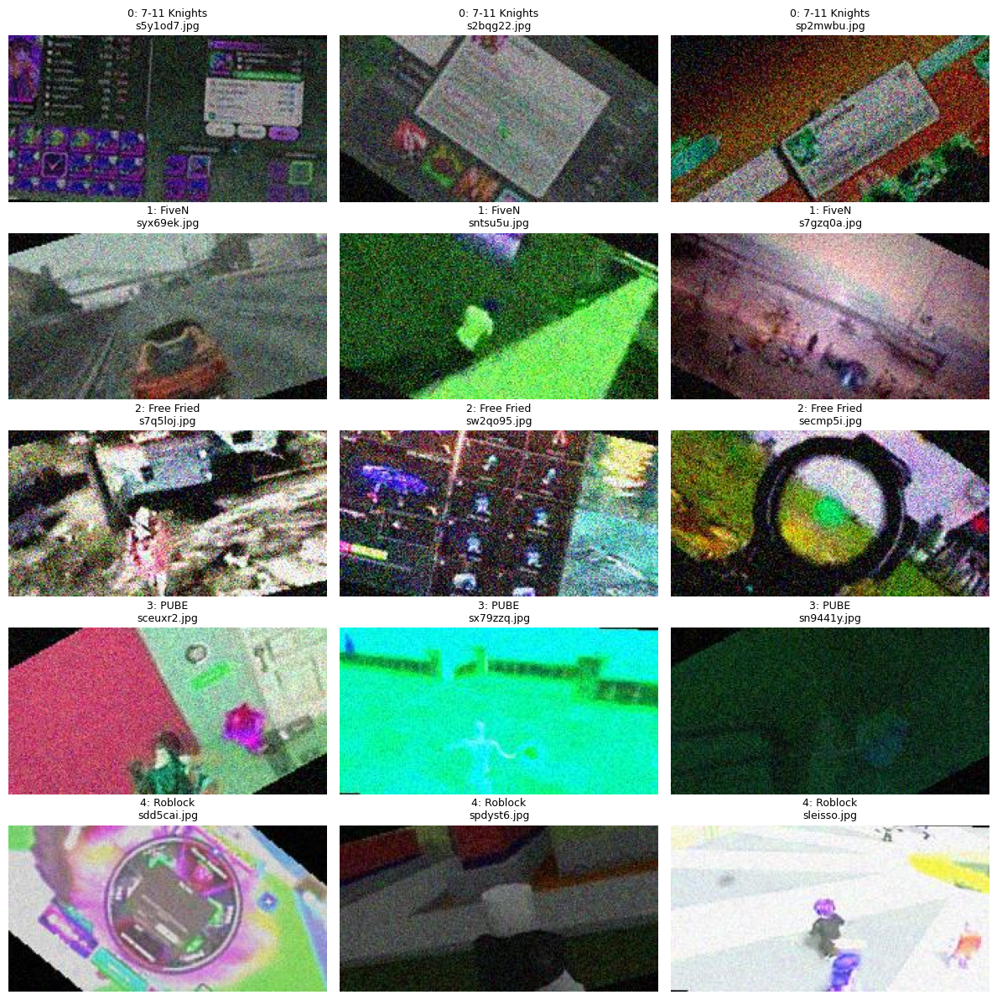

รายละเอียดภาพตัวอย่าง


,file_name,class,width,height,mode,format
0,s5y1od7.jpg,0,230,120,RGB,JPEG
1,s2bqg22.jpg,0,230,120,RGB,JPEG
2,sp2mwbu.jpg,0,230,120,RGB,JPEG
3,syx69ek.jpg,1,230,120,RGB,JPEG
4,sntsu5u.jpg,1,230,120,RGB,JPEG
5,s7gzq0a.jpg,1,230,120,RGB,JPEG
6,s7q5loj.jpg,2,230,120,RGB,JPEG
7,sw2qo95.jpg,2,230,120,RGB,JPEG
8,secmp5i.jpg,2,230,120,RGB,JPEG
9,sceuxr2.jpg,3,230,120,RGB,JPEG


In [3]:
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

CLASS_NAMES = {
    "0": "7-11 Knights",
    "1": "FiveN",
    "2": "Free Fried",
    "3": "PUBE",
    "4": "Roblock",
}

fig, axes = plt.subplots(5, 3, figsize=(12, 12))
image_info = []

for row_number, (label, game_name) in enumerate(CLASS_NAMES.items()):
    samples = train_df.loc[train_df["label"].eq(label)].sample(
        n=3, random_state=342
    )

    for column_number, row in enumerate(samples.itertuples(index=False)):
        path = DATA_DIR / "train" / row.file_name

        with Image.open(path) as source:
            image_info.append({
                "file_name": row.file_name,
                "class": label,
                "width": source.width,
                "height": source.height,
                "mode": source.mode,
                "format": source.format,
            })
            image = ImageOps.exif_transpose(source).convert("RGB")

        ax = axes[row_number, column_number]
        ax.imshow(image)
        ax.set_title(f"{label}: {game_name}\n{row.file_name}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

print("รายละเอียดภาพตัวอย่าง")
display(pd.DataFrame(image_info))

การสำรวจภาพตัวอย่างของเเต่ละคลาส  
สุ่มภาพจากชุดฝึกคลาสละ 3 ภาพ รวม 15 ภาพ โดยกำหนด random_state=342 เพื่อทำให้สุ่มได้ตัวอย่างเดิมเมื่อรันซํ้า พบว่าภาพตัวอย่างทั้งหมดมีขนาด 230×120 พิกเซล ใช้โหมดสี RGB และรูปแบบไฟล์ JPEG

ภาพตัวอย่างหลายภาพมีจุดรบกวน สีผิดเพี้ยน และมุมภาพเอียง โดยบางภาพมีขอบดำ ลักษณะเหล่านี้อาจทำให้การจำแนกเกมยากขึ้น เพราะรายละเอียดของฉาก ตัวละคร และ UI ไม่ชัดเจน

สำหรับการเตรียมข้อมูล ควรหาวิธีปรับขนาดภาพที่รักษาสัดส่วนและองค์ประกอบตามขอบภาพ เช่น letterbox เพราะ HUD และเมนูอาจเป็นข้อมูลที่ช่วยแยกเกมได้ ส่วนการเพิ่ม augmentation เช่น noise หรือการเปลี่ยนสี ควรทดลองและประเมินด้วย validation ก่อน เนื่องจากภาพต้นฉบับมีความผิดเพี้ยนอยู่แล้ว

### 3. ตรวจภาพทั้งชุดว่ามีไฟล์หายหรือเสียหรือไม่

In [4]:
from PIL import Image, ImageFile
import time

# ไม่ยอมให้อ่านภาพที่ข้อมูลขาดหายแบบเงียบ ๆ
ImageFile.LOAD_TRUNCATED_IMAGES = False

records = []
started = time.perf_counter()
total = len(train_df) + len(test_df)

for split, frame in [("train", train_df), ("test", test_df)]:
    for row in frame.itertuples(index=False):
        path = DATA_DIR / split / row.file_name

        record = {
            "split": split,
            "id": row.id,
            "file_name": row.file_name,
            "width": None,
            "height": None,
            "mode": None,
            "format": None,
            "error": "",
        }

        try:
            if not path.is_file():
                raise FileNotFoundError(f"ไม่พบไฟล์: {path}")

            # ตรวจโครงสร้างไฟล์
            with Image.open(path) as image:
                record.update({
                    "width": image.width,
                    "height": image.height,
                    "mode": image.mode,
                    "format": image.format,
                })
                image.verify()

            # เปิดใหม่และ decode จริง เพราะ verify อย่างเดียวไม่เพียงพอ
            with Image.open(path) as image:
                image.load()

        except Exception as exc:
            record["error"] = f"{type(exc).__name__}: {exc}"

        records.append(record)

        if len(records) % 5000 == 0 or len(records) == total:
            elapsed = time.perf_counter() - started
            print(f"ตรวจแล้ว {len(records):,}/{total:,} ภาพ | {elapsed:.1f} วินาที")

image_audit = pd.DataFrame(records)
bad_images = image_audit.loc[image_audit["error"].ne("")]
good_images = image_audit.loc[image_audit["error"].eq("")]

print("\nสรุปการตรวจ")
display(
    image_audit.assign(ok=image_audit["error"].eq(""))
    .groupby("split")
    .agg(total=("id", "size"), readable=("ok", "sum"))
)

print("ขนาดและรูปแบบของภาพที่อ่านได้")
display(
    good_images.groupby(
        ["split", "width", "height", "mode", "format"],
        dropna=False,
    ).size().reset_index(name="images")
)

print("จำนวนภาพที่มีปัญหา:", len(bad_images))
if not bad_images.empty:
    display(bad_images[["split", "id", "file_name", "error"]].head(20))

assert bad_images.empty, "พบภาพมีปัญหา ให้ตรวจรายละเอียดก่อนดำเนินการต่อ"
print("ตรวจภาพทั้งชุดผ่าน")

ตรวจแล้ว 5,000/57,435 ภาพ | 64.1 วินาที
ตรวจแล้ว 10,000/57,435 ภาพ | 127.9 วินาที
ตรวจแล้ว 15,000/57,435 ภาพ | 192.4 วินาที
ตรวจแล้ว 20,000/57,435 ภาพ | 257.3 วินาที
ตรวจแล้ว 25,000/57,435 ภาพ | 322.2 วินาที
ตรวจแล้ว 30,000/57,435 ภาพ | 386.5 วินาที
ตรวจแล้ว 35,000/57,435 ภาพ | 450.1 วินาที
ตรวจแล้ว 40,000/57,435 ภาพ | 513.4 วินาที
ตรวจแล้ว 45,000/57,435 ภาพ | 577.5 วินาที
ตรวจแล้ว 50,000/57,435 ภาพ | 640.5 วินาที
ตรวจแล้ว 55,000/57,435 ภาพ | 705.4 วินาที
ตรวจแล้ว 57,435/57,435 ภาพ | 736.0 วินาที

สรุปการตรวจ


,total,readable
split,,
test,25889,25889
train,31546,31546


ขนาดและรูปแบบของภาพที่อ่านได้


,split,width,height,mode,format,images
0,test,230,120,RGB,JPEG,25889
1,train,230,120,RGB,JPEG,31546


จำนวนภาพที่มีปัญหา: 0
ตรวจภาพทั้งชุดผ่าน


### 4.1 ตรวจภาพซ้ำแบบตรงกันใน Train

ต้องตรวจก่อนแบ่ง validation เพราะถ้าภาพเดียวกันอยู่ทั้งสองฝั่ง คะแนนอาจสูงเกินความสามารถจริงของโมเดล

ตรวจสองแบบ:
- ไฟล์เหมือนกันทุก byte: ใช้ SHA256 ของไฟล์
- พิกเซลเหมือนกัน: ตรวจภาพหลัง decode ซึ่งช่วยจับกรณีไฟล์ต่างกันแต่แสดงภาพเหมือนกัน

In [5]:
import hashlib
from PIL import Image, ImageOps

duplicate_records = []

for number, row in enumerate(train_df.itertuples(index=False), start=1):
    path = DATA_DIR / "train" / row.file_name

    file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

    with Image.open(path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        pixel_data = (
            f"{image.width},{image.height}|RGB|".encode()
            + image.tobytes()
        )
        pixel_hash = hashlib.sha256(pixel_data).hexdigest()

    duplicate_records.append({
        "id": row.id,
        "file_name": row.file_name,
        "label": row.label,
        "file_sha256": file_hash,
        "pixel_sha256": pixel_hash,
    })

    if number % 5000 == 0 or number == len(train_df):
        print(f"ตรวจแล้ว {number:,}/{len(train_df):,} ภาพ")

train_hashes = pd.DataFrame(duplicate_records)

for column in ["file_sha256", "pixel_sha256"]:
    sizes = train_hashes.groupby(column).size()
    duplicate_sizes = sizes.loc[sizes.gt(1)]

    print(f"\n{column}")
    print("จำนวนกลุ่มภาพซ้ำ:", len(duplicate_sizes))
    print("จำนวนภาพในกลุ่มซ้ำ:", int(duplicate_sizes.sum()))
    print("จำนวนสำเนาที่เกินจากกลุ่มละหนึ่งภาพ:",
          int((duplicate_sizes - 1).sum()))

# ตรวจว่าภาพที่พิกเซลเหมือนกันมี labels ขัดแย้งหรือไม่
label_counts = train_hashes.groupby("pixel_sha256")["label"].nunique()
conflict_hashes = label_counts.loc[label_counts.gt(1)].index

conflicting_images = train_hashes.loc[
    train_hashes["pixel_sha256"].isin(conflict_hashes)
]

print("\nจำนวนกลุ่มภาพเหมือนกันแต่ label ขัดแย้ง:", len(conflict_hashes))

if not conflicting_images.empty:
    display(
        conflicting_images.sort_values("pixel_sha256")
        [["id", "file_name", "label", "pixel_sha256"]]
        .head(20)
    )

assert conflicting_images.empty, \
    "พบ label ขัดแย้ง ต้องตรวจภาพก่อนดำเนินการต่อ"

print("\nตรวจภาพซ้ำแบบตรงกันเสร็จแล้ว")

ตรวจแล้ว 5,000/31,546 ภาพ
ตรวจแล้ว 10,000/31,546 ภาพ
ตรวจแล้ว 15,000/31,546 ภาพ
ตรวจแล้ว 20,000/31,546 ภาพ
ตรวจแล้ว 25,000/31,546 ภาพ
ตรวจแล้ว 30,000/31,546 ภาพ
ตรวจแล้ว 31,546/31,546 ภาพ

file_sha256
จำนวนกลุ่มภาพซ้ำ: 0
จำนวนภาพในกลุ่มซ้ำ: 0
จำนวนสำเนาที่เกินจากกลุ่มละหนึ่งภาพ: 0

pixel_sha256
จำนวนกลุ่มภาพซ้ำ: 0
จำนวนภาพในกลุ่มซ้ำ: 0
จำนวนสำเนาที่เกินจากกลุ่มละหนึ่งภาพ: 0

จำนวนกลุ่มภาพเหมือนกันแต่ label ขัดแย้ง: 0

ตรวจภาพซ้ำแบบตรงกันเสร็จแล้ว


### 4.2 เตรียมเครื่องมือตรวจภาพเกือบเหมือนกัน
ภาพที่ต่างกันเล็กน้อยด้านสี ความสว่าง หรือรายละเอียด ซึ่ง SHA256 จับไม่ได้

ใช้ ImageHash คำนวณ:
- pHash: เปรียบเทียบโครงสร้างภาพโดยรวม
- dHash: เปรียบเทียบรูปแบบการเปลี่ยนความสว่าง

In [7]:
import imagehash
from importlib.metadata import version

sample_path = DATA_DIR / "train" / train_df.iloc[0]["file_name"]

with Image.open(sample_path) as source:
    image = ImageOps.exif_transpose(source).convert("RGB")
    print("ImageHash version:", version("ImageHash"))
    print("pHash:", imagehash.phash(image, hash_size=8))
    print("dHash:", imagehash.dhash(image, hash_size=8))

ImageHash version: 4.3.2
pHash: d267131c0e107f6f
dHash: 0a8a49a061b0d8f8


### 4.3 คำนวณ pHash และ dHash ของภาพ Train ทั้งชุด

In [8]:
import time

perceptual_records = []
started = time.perf_counter()

for number, row in enumerate(train_df.itertuples(index=False), start=1):
    path = DATA_DIR / "train" / row.file_name

    with Image.open(path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")

        perceptual_records.append({
            "id": row.id,
            "phash": str(imagehash.phash(image, hash_size=8)),
            "dhash": str(imagehash.dhash(image, hash_size=8)),
        })

    if number % 5000 == 0 or number == len(train_df):
        elapsed = time.perf_counter() - started
        print(
            f"คำนวณแล้ว {number:,}/{len(train_df):,} ภาพ "
            f"| {elapsed:.1f} วินาที"
        )

perceptual_hashes = pd.DataFrame(perceptual_records)

assert len(perceptual_hashes) == len(train_df)
assert perceptual_hashes["id"].is_unique
assert perceptual_hashes.notna().all().all()
assert perceptual_hashes["id"].tolist() == train_df["id"].tolist()

print("\nจำนวนภาพที่คำนวณ:", len(perceptual_hashes))
display(perceptual_hashes.head())
print("คำนวณ perceptual hashes ครบแล้ว")

คำนวณแล้ว 5,000/31,546 ภาพ | 10.4 วินาที
คำนวณแล้ว 10,000/31,546 ภาพ | 20.2 วินาที
คำนวณแล้ว 15,000/31,546 ภาพ | 29.9 วินาที
คำนวณแล้ว 20,000/31,546 ภาพ | 39.6 วินาที
คำนวณแล้ว 25,000/31,546 ภาพ | 49.2 วินาที
คำนวณแล้ว 30,000/31,546 ภาพ | 58.3 วินาที
คำนวณแล้ว 31,546/31,546 ภาพ | 61.5 วินาที

จำนวนภาพที่คำนวณ: 31546


,id,phash,dhash
0,PLY00001,d267131c0e107f6f,0a8a49a061b0d8f8
1,PLY00002,942342b5de556b8e,d1c5e3347c983cac
2,PLY00003,85b054f778f078d2,fceaf9f9e8eaeafa
3,PLY00004,918817a54e9f6a37,f3e2e9e1d1185858
4,PLY00005,c27ec670bb4155aa,2d2466d3998bcbc8


คำนวณ perceptual hashes ครบแล้ว


### 4.4 ค้นหาและจัดกลุ่มภาพคล้ายใน Train
ใช้เงื่อนไขเบื้องต้น pHash ต่างกันไม่เกิน 4 บิต และ dHash ต่างกันไม่เกิน 8 บิต พร้อมกัน เกณฑ์นี้เป็น heuristic สำหรับคัดภาพมาตรวจด้วยตา ยังไม่ยืนยันว่าทุกคู่ซ้ำกันจริง

In [9]:
from collections import defaultdict

PHASH_RADIUS = 4
DHASH_RADIUS = 8

# Union-Find: รวมภาพที่เชื่อมโยงกันให้อยู่ในกลุ่มเดียว
parent = list(range(len(train_df)))

def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(left, right):
    left_root, right_root = find(left), find(right)
    if left_root != right_root:
        parent[right_root] = left_root


# BK-tree: ค้นหา pHash ที่อยู่ใกล้กัน
class BKTree:
    def __init__(self):
        self.root = None

    def add(self, value):
        if self.root is None:
            self.root = (value, {})
            return

        node = self.root
        while True:
            distance = (value ^ node[0]).bit_count()
            if distance == 0:
                return
            if distance not in node[1]:
                node[1][distance] = (value, {})
                return
            node = node[1][distance]

    def query(self, value, radius):
        stack = [] if self.root is None else [self.root]

        while stack:
            node = stack.pop()
            distance = (value ^ node[0]).bit_count()

            if distance <= radius:
                yield node[0], distance

            for edge, child in node[1].items():
                if distance - radius <= edge <= distance + radius:
                    stack.append(child)


assert perceptual_hashes["id"].tolist() == train_df["id"].tolist()

tree = BKTree()
buckets = defaultdict(dict)
edges = []

for index, row in enumerate(perceptual_hashes.itertuples(index=False)):
    phash = int(row.phash, 16)
    dhash = int(row.dhash, 16)

    for candidate_phash, phash_distance in tree.query(phash, PHASH_RADIUS):
        for candidate_dhash, other_index in buckets[candidate_phash].items():
            dhash_distance = (dhash ^ candidate_dhash).bit_count()

            if dhash_distance <= DHASH_RADIUS:
                union(index, other_index)
                edges.append({
                    "left_index": other_index,
                    "right_index": index,
                    "phash_distance": phash_distance,
                    "dhash_distance": dhash_distance,
                })

    if phash not in buckets:
        tree.add(phash)

    # เก็บตัวแทนเมื่อ pHash และ dHash ตรงกันทั้งคู่
    buckets[phash].setdefault(dhash, index)

    if (index + 1) % 5000 == 0 or index + 1 == len(train_df):
        print(f"ค้นหาแล้ว {index + 1:,}/{len(train_df):,} ภาพ")


train_grouped = train_df.copy()
train_grouped["duplicate_group"] = [
    find(index) for index in range(len(train_df))
]

near_duplicate_edges = pd.DataFrame(
    edges,
    columns=[
        "left_index", "right_index",
        "phash_distance", "dhash_distance",
    ],
)

group_sizes = train_grouped.groupby("duplicate_group").size()
similar_groups = group_sizes.loc[group_sizes.gt(1)]

labels_per_group = train_grouped.groupby("duplicate_group")["label"].nunique()
mixed_label_groups = labels_per_group.loc[labels_per_group.gt(1)]

print("\nจำนวนกลุ่มทั้งหมด รวมภาพเดี่ยว:", len(group_sizes))
print("จำนวนกลุ่มที่มีภาพคล้ายตั้งแต่ 2 ภาพ:", len(similar_groups))
print("จำนวนภาพในกลุ่มภาพคล้าย:", int(similar_groups.sum()))
print("ขนาดกลุ่มใหญ่ที่สุด:", int(group_sizes.max()))
print("จำนวนกลุ่มภาพคล้ายที่มีหลาย labels:", len(mixed_label_groups))

display(near_duplicate_edges.head(10))

ค้นหาแล้ว 5,000/31,546 ภาพ
ค้นหาแล้ว 10,000/31,546 ภาพ
ค้นหาแล้ว 15,000/31,546 ภาพ
ค้นหาแล้ว 20,000/31,546 ภาพ
ค้นหาแล้ว 25,000/31,546 ภาพ
ค้นหาแล้ว 30,000/31,546 ภาพ
ค้นหาแล้ว 31,546/31,546 ภาพ

จำนวนกลุ่มทั้งหมด รวมภาพเดี่ยว: 30685
จำนวนกลุ่มที่มีภาพคล้ายตั้งแต่ 2 ภาพ: 458
จำนวนภาพในกลุ่มภาพคล้าย: 1319
ขนาดกลุ่มใหญ่ที่สุด: 41
จำนวนกลุ่มภาพคล้ายที่มีหลาย labels: 0


,left_index,right_index,phash_distance,dhash_distance
0,679,1372,4,4
1,605,1617,2,1
2,1176,1655,4,7
3,577,1754,4,7
4,1748,1925,2,1
5,1562,2355,4,2
6,1748,2359,2,0
7,1925,2359,2,1
8,1315,2657,4,1
9,605,3038,4,2


### 4.5 ดูคู่ภาพที่ตรวจพบ

6 คู่ โดยเลือกทั้งคู่ที่ hash ใกล้กันมากและคู่ที่อยู่ใกล้ขอบเกณฑ์ เพื่อไม่ดูเฉพาะตัวอย่างที่คล้ายชัดเจนที่สุด

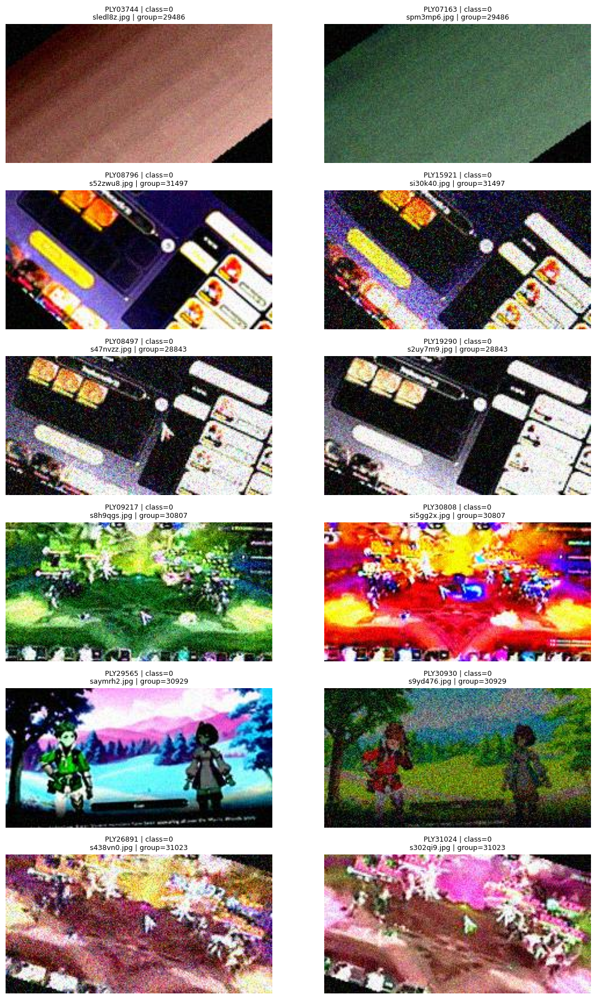

In [10]:
# เลือกคู่ที่ใกล้กันมาก 3 คู่ และใกล้ขอบเกณฑ์ 3 คู่
ordered_edges = near_duplicate_edges.sort_values(
    ["phash_distance", "dhash_distance"]
)

review_pairs = pd.concat([
    ordered_edges.head(3),
    ordered_edges.tail(3),
]).drop_duplicates(["left_index", "right_index"])

if review_pairs.empty:
    print("ไม่มีคู่ภาพให้ตรวจ")
else:
    fig, axes = plt.subplots(
        len(review_pairs), 2,
        figsize=(12, 3 * len(review_pairs)),
        squeeze=False,
    )

    for row_number, pair in enumerate(
        review_pairs.itertuples(index=False)
    ):
        for column_number, image_index in enumerate(
            [pair.left_index, pair.right_index]
        ):
            row = train_grouped.iloc[int(image_index)]
            path = DATA_DIR / "train" / row["file_name"]

            with Image.open(path) as source:
                image = ImageOps.exif_transpose(source).convert("RGB")

            ax = axes[row_number, column_number]
            ax.imshow(image)
            ax.set_title(
                f'{row["id"]} | class={row["label"]}\n'
                f'{row["file_name"]} | group={row["duplicate_group"]}',
                fontsize=9,
            )
            ax.axis("off")

        axes[row_number, 0].set_ylabel(
            f"pHash={pair.phash_distance}\n"
            f"dHash={pair.dhash_distance}"
        )

    plt.tight_layout()
    plt.show()

คู่แรกมีรายละเอียดน้อยมาก จึงยืนยันความซ้ำจากภาพได้ยาก และทั้ง 6 คู่ที่แสดงเป็นคลาส 0 จึงยังไม่ครอบคลุมทุกคลาส เราจะใช้กลุ่มที่ตรวจพบเป็นมาตรการลดความเสี่ยง โดยไม่ลบภาพหรือแก้ labels ทั้งนี้ hash อาจพลาดภาพคล้ายบางคู่ได้

### 5 แบ่ง Train–Validation โดยรักษากลุ่มภาพคล้าย

ใช้ข้อมูล Train แบ่งประมาณ 80% สำหรับฝึก / 20% สำหรับ validation ด้วย StratifiedGroupKFold ซึ่งพยายามรักษาสัดส่วนคลาสและไม่แยกสมาชิกกลุ่มเดียวกันข้ามฝั่ง เราจะกำหนด seed และใช้ fold แรกไว้ล่วงหน้า ไม่เลือก split ตามคะแนนโมเดล

In [11]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

SEED = 342

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

fit_indices, val_indices = next(
    splitter.split(
        X=train_grouped,
        y=train_grouped["label"],
        groups=train_grouped["duplicate_group"],
    )
)

fit_df = train_grouped.iloc[np.sort(fit_indices)].copy()
val_df = train_grouped.iloc[np.sort(val_indices)].copy()

# ตรวจว่าแถวและกลุ่มไม่ข้ามฝั่ง
assert set(fit_df["id"]).isdisjoint(set(val_df["id"]))
assert set(fit_df["duplicate_group"]).isdisjoint(
    set(val_df["duplicate_group"])
)
assert len(fit_df) + len(val_df) == len(train_grouped)
assert set(fit_df["label"]) == set(val_df["label"]) == {
    "0", "1", "2", "3", "4"
}

# ตรวจซ้ำด้วย pixel hashes จากขั้นก่อนหน้า
pixel_by_id = train_hashes.set_index("id")["pixel_sha256"]
assert set(fit_df["id"]).issubset(pixel_by_id.index)
assert set(val_df["id"]).issubset(pixel_by_id.index)

assert set(pixel_by_id.loc[fit_df["id"]]).isdisjoint(
    set(pixel_by_id.loc[val_df["id"]])
)

split_summary = pd.DataFrame({
    "fit_images": fit_df["label"].value_counts(),
    "validation_images": val_df["label"].value_counts(),
}).sort_index()

split_summary["fit_percent"] = (
    split_summary["fit_images"] / len(fit_df) * 100
).round(2)

split_summary["validation_percent"] = (
    split_summary["validation_images"] / len(val_df) * 100
).round(2)

print(f"Fit: {len(fit_df):,} ภาพ")
print(f"Validation: {len(val_df):,} ภาพ")
print(f"Validation fraction: {len(val_df) / len(train_grouped):.2%}")

display(split_summary)

print("กลุ่มภาพคล้ายข้ามฝั่ง: 0")
print("ภาพพิกเซลเหมือนกันข้ามฝั่ง: 0")
print("ตรวจ split ผ่าน")

Fit: 25,236 ภาพ
Validation: 6,310 ภาพ
Validation fraction: 20.00%


,fit_images,validation_images,fit_percent,validation_percent
label,,,,
0,9943,2486,39.40,39.40
1,3525,882,13.97,13.98
2,4477,1119,17.74,17.73
3,4741,1185,18.79,18.78
4,2550,638,10.10,10.11


กลุ่มภาพคล้ายข้ามฝั่ง: 0
ภาพพิกเซลเหมือนกันข้ามฝั่ง: 0
ตรวจ split ผ่าน


### 6 บันทึก split เพื่อใช้กับทุกโมเดล
เราจะเก็บ ID, ชื่อภาพ, label, กลุ่ม และฝั่งที่แบ่งไว้ เพื่อให้เปรียบเทียบโมเดลบนข้อมูลชุดเดียวกัน รวมถึงนำไปใช้ต่อบน Kaggle

In [12]:
import hashlib
import json

SPLIT_DIR = PROJECT_ROOT / "reports" / "experiments" / "task4"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

split_manifest = train_grouped[
    ["id", "file_name", "label", "duplicate_group"]
].copy()

split_manifest["subset"] = np.where(
    split_manifest["id"].isin(val_df["id"]),
    "validation",
    "fit",
)

assert split_manifest["id"].is_unique
assert len(split_manifest) == len(train_df)
assert split_manifest.groupby("duplicate_group")["subset"].nunique().max() == 1

# สร้างเนื้อหาไฟล์ที่แน่นอน และไม่เขียนทับ split ที่ต่างจากเดิม
csv_content = split_manifest.to_csv(index=False, lineterminator="\n")
csv_bytes = csv_content.encode("utf-8")
split_path = SPLIT_DIR / "split_manifest.csv"

if split_path.exists() and split_path.read_bytes() != csv_bytes:
    raise FileExistsError(
        "มี split_manifest.csv ที่เนื้อหาต่างกันอยู่แล้ว "
        "ให้ตรวจสอบก่อน ไม่เขียนทับ"
    )

split_path.write_bytes(csv_bytes)

metadata = {
    "seed": SEED,
    "method": "StratifiedGroupKFold",
    "n_splits": 5,
    "selected_fold": 0,
    "phash_radius": PHASH_RADIUS,
    "dhash_radius": DHASH_RADIUS,
    "fit_images": len(fit_df),
    "validation_images": len(val_df),
    "train_csv_sha256": hashlib.sha256(
        (DATA_DIR / "train.csv").read_bytes()
    ).hexdigest(),
    "split_manifest_sha256": hashlib.sha256(csv_bytes).hexdigest(),
    "versions": {
        package: version(package)
        for package in ["pandas", "numpy", "scikit-learn", "ImageHash", "Pillow"]
    },
}

metadata_path = SPLIT_DIR / "split_metadata.json"
metadata_path.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# อ่านกลับเพื่อยืนยันว่าบันทึกครบและลำดับไม่เปลี่ยน
saved = pd.read_csv(split_path, dtype=str, keep_default_na=False)

assert saved["id"].tolist() == train_df["id"].tolist()
assert saved["subset"].value_counts().to_dict() == {
    "fit": len(fit_df),
    "validation": len(val_df),
}

print("บันทึก:", split_path)
print("บันทึก:", metadata_path)
display(saved.head())
print("บันทึกและตรวจ split ผ่าน")

บันทึก: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\reports\experiments\task4\split_manifest.csv
บันทึก: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\reports\experiments\task4\split_metadata.json


,id,file_name,label,duplicate_group,subset
0,PLY00001,su7tkav.jpg,0,0,fit
1,PLY00002,shlk51f.jpg,4,1,fit
2,PLY00003,sbdqvs0.jpg,0,2,fit
3,PLY00004,s6oe1m9.jpg,2,3,fit
4,PLY00005,skn51jb.jpg,0,4,fit


บันทึกและตรวจ split ผ่าน


### 7 ตรวจ PyTorch และ CUDA
ติดตั้ง dependencies จากส่วนต้นของ notebook ก่อนรันส่วนนี้


In [15]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "PyTorch ยังใช้ GPU ไม่ได้"

print("GPU:", torch.cuda.get_device_name(0))
print(
    "VRAM:",
    round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2),
    "GiB",
)

# ทดลองคำนวณขนาดเล็กบน GPU ยังไม่ใช่การฝึกโมเดล
x = torch.ones((32, 32), device="cuda")
y = x @ x
torch.cuda.synchronize()

assert y[0, 0].item() == 32.0
print("GPU calculation: ผ่าน")

del x, y
torch.cuda.empty_cache()

PyTorch: 2.9.1+cu128
TorchVision: 0.24.1+cu128
CUDA runtime: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM: 6.0 GiB
GPU calculation: ผ่าน


### 8 อ่านกลับและยืนยัน split ที่บันทึกไว้


In [16]:
from pathlib import Path
import hashlib
import json
import pandas as pd

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        folder
        for folder in [cwd, *cwd.parents]
        if (folder / "data/raw/Task4/train.csv").is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, "ไม่พบ project root"

DATA_DIR = PROJECT_ROOT / "data/raw/Task4"
SPLIT_DIR = PROJECT_ROOT / "reports/experiments/task4"

split_path = SPLIT_DIR / "split_manifest.csv"
metadata = json.loads(
    (SPLIT_DIR / "split_metadata.json").read_text(encoding="utf-8")
)

# ยืนยันว่า CSV และ split ยังเป็นไฟล์เดียวกับตอนบันทึก
for path, expected_hash in [
    (DATA_DIR / "train.csv", metadata["train_csv_sha256"]),
    (split_path, metadata["split_manifest_sha256"]),
]:
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual_hash == expected_hash, f"ไฟล์เปลี่ยน: {path.name}"

train_df = pd.read_csv(
    DATA_DIR / "train.csv", dtype=str, keep_default_na=False
)
test_df = pd.read_csv(
    DATA_DIR / "test.csv", dtype=str, keep_default_na=False
)
split_manifest = pd.read_csv(
    split_path, dtype=str, keep_default_na=False
)

# ตรวจว่า split ตรงกับข้อมูล Train ทั้ง ID, ชื่อภาพ และ label
pd.testing.assert_frame_equal(
    split_manifest[["id", "file_name", "label"]].reset_index(drop=True),
    train_df[["id", "file_name", "label"]].reset_index(drop=True),
)

assert split_manifest["id"].is_unique
assert set(split_manifest["subset"]) == {"fit", "validation"}

fit_df = split_manifest.loc[
    split_manifest["subset"].eq("fit")
].copy().reset_index(drop=True)

val_df = split_manifest.loc[
    split_manifest["subset"].eq("validation")
].copy().reset_index(drop=True)

assert len(fit_df) == metadata["fit_images"]
assert len(val_df) == metadata["validation_images"]
assert set(fit_df["id"]).isdisjoint(val_df["id"])
assert set(fit_df["duplicate_group"]).isdisjoint(
    val_df["duplicate_group"]
)

print("Project:", PROJECT_ROOT)
print(f"Fit: {len(fit_df):,} ภาพ")
print(f"Validation: {len(val_df):,} ภาพ")
print(f"Test: {len(test_df):,} ภาพ")
print("โหลด split เดิมและตรวจ SHA256 ผ่าน")

Project: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML
Fit: 25,236 ภาพ
Validation: 6,310 ภาพ
Test: 25,889 ภาพ
โหลด split เดิมและตรวจ SHA256 ผ่าน


### 9 เตรียมภาพและทดสอบอ่านหนึ่ง batch

เราจะปรับภาพเป็น สูง 128 × กว้าง 256 ด้วย letterbox เพื่อรักษาสัดส่วนและไม่ตัด HUD ตามขอบภาพ พร้อมเพิ่มการเปลี่ยนสีเล็กน้อยเฉพาะฝั่ง Fit ส่วน Validation จะไม่มีการสุ่ม augmentation

In [17]:
import random
import numpy as np
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 342
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

IMAGE_SIZE = (128, 256)  # สูง, กว้าง
BATCH_SIZE = 16

# ค่าที่จะใช้ร่วมกับ pretrained ImageNet backbone
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


class Letterbox:
    def __init__(self, size):
        self.height, self.width = size

    def __call__(self, image):
        scale = min(
            self.width / image.width,
            self.height / image.height,
        )
        resized = image.resize(
            (
                max(1, round(image.width * scale)),
                max(1, round(image.height * scale)),
            ),
            Image.Resampling.BILINEAR,
        )

        canvas = Image.new(
            "RGB",
            (self.width, self.height),
            tuple(round(value * 255) for value in MEAN),
        )
        canvas.paste(
            resized,
            (
                (self.width - resized.width) // 2,
                (self.height - resized.height) // 2,
            ),
        )
        return canvas


fit_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.12,
            contrast=0.12,
            saturation=0.08,
            hue=0.01,
        )
    ], p=0.7),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transform = transforms.Compose([
    Letterbox(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class GameDataset(Dataset):
    def __init__(self, frame, image_root, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.image_root = image_root
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        path = self.image_root / row["file_name"]

        with Image.open(path) as source:
            image = ImageOps.exif_transpose(source).convert("RGB")
            tensor = self.transform(image)

        return tensor, int(row["label"])


fit_dataset = GameDataset(
    fit_df, DATA_DIR / "train", fit_transform
)
val_dataset = GameDataset(
    val_df, DATA_DIR / "train", val_transform
)

fit_loader = DataLoader(
    fit_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

# ทดสอบอ่านเพียงหนึ่ง batch ของแต่ละฝั่ง
for name, loader in [("Fit", fit_loader), ("Validation", val_loader)]:
    images, labels = next(iter(loader))

    assert images.shape == (BATCH_SIZE, 3, *IMAGE_SIZE)
    assert images.dtype == torch.float32
    assert torch.isfinite(images).all()
    assert labels.dtype == torch.int64
    assert ((labels >= 0) & (labels <= 4)).all()

    print(f"{name} images:", tuple(images.shape))
    print(f"{name} labels:", labels.tolist())

print("DataLoader smoke test: ผ่าน")

Fit images: (16, 3, 128, 256)
Fit labels: [0, 0, 0, 1, 3, 0, 3, 1, 0, 2, 1, 2, 2, 1, 2, 3]
Validation images: (16, 3, 128, 256)
Validation labels: [1, 0, 2, 3, 0, 0, 4, 1, 2, 1, 2, 3, 3, 0, 0, 0]
DataLoader smoke test: ผ่าน


### 10 เตรียม ResNet18 และทดสอบโมเดลหนึ่ง batch

เราจะใช้ ResNet18 ที่มีน้ำหนัก ImageNet IMAGENET1K_V1 แล้วเปลี่ยนชั้นสุดท้ายให้จำแนกเกม 5 คลาส

In [18]:
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights

DEVICE = torch.device("cuda")
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# โหลด pretrained backbone และเปลี่ยน classifier เป็น 5 คลาส
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, 5)
model = model.to(DEVICE)

# ทดสอบด้วย Validation เพื่อไม่สุ่ม augmentation
model.eval()
images, labels = next(iter(val_loader))

torch.cuda.reset_peak_memory_stats()

with torch.inference_mode():
    logits = model(images.to(DEVICE, non_blocking=True))

assert logits.shape == (len(images), 5)
assert torch.isfinite(logits).all()

print("Device:", DEVICE)
print("Model: ResNet18")
print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(logits.shape))
print(
    "Parameters:",
    f"{sum(parameter.numel() for parameter in model.parameters()):,}",
)
print(
    "Peak GPU allocated memory:",
    f"{torch.cuda.max_memory_allocated() / 2**20:.1f} MiB",
)
print("Model forward test: ผ่าน")

del images, labels, logits
torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Kittithat/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Device: cuda
Model: ResNet18
Input shape: (16, 3, 128, 256)
Output shape: (16, 5)
Parameters: 11,179,077
Peak GPU allocated memory: 121.3 MiB
Model forward test: ผ่าน


### กำหนดแผนฝึกและฟังก์ชันประเมิน

| รายการ | ค่าเริ่มต้น |
|---|---|
| จำนวน epochs สูงสุด | 20 |
| Warmup | 2 epochs แรกฝึกเฉพาะ classifier |
| หลัง warmup | Fine-tune ทั้งโมเดล |
| Batch / Effective batch | 16 / 64 ด้วย gradient accumulation |
| Learning rate | Head `0.001`, backbone `0.0001` |
| เลือก checkpoint | Validation Macro F1 สูงสุด |
| Early stopping | หยุดเมื่อไม่ดีขึ้น 6 epochs |

In [20]:
from sklearn.metrics import f1_score, accuracy_score
from torch.nn import functional as F

TRAIN_CONFIG = {
    "seed": SEED,
    "epochs": 20,
    "warmup_epochs": 2,
    "batch_size": BATCH_SIZE,
    "effective_batch": 64,
    "head_lr": 1e-3,
    "backbone_lr": 1e-4,
    "weight_decay": 1e-4,
    "patience": 6,
    "amp": True,
}

assert TRAIN_CONFIG["effective_batch"] % BATCH_SIZE == 0

CLASS_NAMES = [
    "7-11 Knights",
    "FiveN",
    "Free Fried",
    "PUBE",
    "Roblock",
]


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    all_probabilities = []
    all_labels = []
    loss_sum = 0.0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=TRAIN_CONFIG["amp"],
        ):
            logits = model(images)

        # คำนวณ loss และ probabilities ด้วย float32
        logits = logits.float()
        assert torch.isfinite(logits).all()

        loss_sum += F.cross_entropy(
            logits, labels, reduction="sum"
        ).item()

        all_probabilities.append(logits.softmax(dim=1).cpu().numpy())
        all_labels.append(labels.cpu().numpy())

    probabilities = np.concatenate(all_probabilities)
    targets = np.concatenate(all_labels)
    predictions = probabilities.argmax(axis=1)

    metrics = {
        "val_loss": loss_sum / len(targets),
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets,
            predictions,
            labels=list(range(5)),
            average="macro",
            zero_division=0,
        ),
        "per_class_f1": f1_score(
            targets,
            predictions,
            labels=list(range(5)),
            average=None,
            zero_division=0,
        ).tolist(),
    }

    return metrics, probabilities


display(pd.Series(TRAIN_CONFIG, name="value").to_frame())
print("เตรียม config และฟังก์ชัน evaluate แล้ว — ยังไม่เริ่มฝึก")

,value
seed,342
epochs,20
warmup_epochs,2
batch_size,16
effective_batch,64
head_lr,0.001
backbone_lr,0.0001
weight_decay,0.0001
patience,6
amp,True


เตรียม config และฟังก์ชัน evaluate แล้ว — ยังไม่เริ่มฝึก


กำหนดให้ฝึก classifier ใหม่ก่อน 2 epochs แล้วจึง fine-tune backbone ด้วย learning rate ต่ำกว่า classifier เพื่อลดการเปลี่ยนน้ำหนัก pretrained อย่างรวดเร็ว ใช้ gradient accumulation รวม batch ละ 16 ภาพให้มี effective batch เป้าหมาย 64 ภาพ และใช้ mixed precision เพื่อลดหน่วยความจำ เลือก checkpoint ด้วย validation Macro F1 โดยติดตาม F1 แยกคลาสร่วมด้วย เนื่องจากจำนวนภาพแต่ละคลาสไม่สมดุล การประเมินนี้ใช้ development validation ที่แบ่งไว้ จึงไม่ใช่คะแนน Kaggle หรือผลประเมินอิสระหลังเลือกโมเดล

### เตรียมฟังก์ชันฝึกหนึ่ง epoch

In [21]:
import time


def train_one_epoch(model, loader, optimizer, scaler, epoch):
    started = time.perf_counter()
    model.train()

    # epoch เริ่มนับจาก 0: สองรอบแรกฝึกเฉพาะ classifier
    warmup = epoch < TRAIN_CONFIG["warmup_epochs"]

    for parameter in model.parameters():
        parameter.requires_grad_(not warmup)

    for parameter in model.fc.parameters():
        parameter.requires_grad_(True)

    if warmup:
        # คง running statistics ของ BatchNorm ใน pretrained backbone
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()

    accumulation_steps = (
        TRAIN_CONFIG["effective_batch"] // loader.batch_size
    )

    assert not loader.drop_last
    optimizer.zero_grad(set_to_none=True)

    total_loss = 0.0
    samples_seen = 0

    for step, (images, labels) in enumerate(loader):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        # จำนวนภาพจริงในกลุ่ม accumulation รวมกลุ่มสุดท้าย
        group_start = (step // accumulation_steps) * accumulation_steps
        group_end = min(
            group_start + accumulation_steps, len(loader)
        )
        group_samples = min(
            len(loader.dataset) - group_start * loader.batch_size,
            (group_end - group_start) * loader.batch_size,
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=TRAIN_CONFIG["amp"],
        ):
            logits = model(images)
            loss_sum = F.cross_entropy(
                logits, labels, reduction="sum"
            )
            loss = loss_sum / group_samples

        if not torch.isfinite(loss):
            raise FloatingPointError(
                "Training loss ไม่เป็นค่าจำกัด ให้หยุดตรวจข้อมูลและ LR"
            )

        scaler.scale(loss).backward()

        update_now = (
            (step + 1) % accumulation_steps == 0
            or step + 1 == len(loader)
        )

        if update_now:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        total_loss += loss_sum.detach().float().item()
        samples_seen += len(labels)

        if (step + 1) % 400 == 0 or step + 1 == len(loader):
            print(
                f"Epoch {epoch + 1} | "
                f"batch {step + 1}/{len(loader)} | "
                f"train loss {total_loss / samples_seen:.4f}"
            )

    assert samples_seen == len(loader.dataset)

    return {
        "train_loss": total_loss / samples_seen,
        "train_seconds": time.perf_counter() - started,
    }


print("เตรียม train_one_epoch แล้ว — ยังไม่เริ่มฝึก")

เตรียม train_one_epoch แล้ว — ยังไม่เริ่มฝึก


ในช่วง warmup จะฝึกเฉพาะ classifier และคงสถิติ BatchNorm ของ backbone จาก pretrained weights หลัง warmup จึงเปิดให้ปรับน้ำหนักทั้งโมเดล ใช้ mixed precision ร่วมกับ gradient scaling และสะสม gradients เพื่อให้ effective batch เป้าหมายเท่ากับ 64 ภาพ โดยหาร loss ด้วยจำนวนภาพจริงในแต่ละกลุ่ม รวมกลุ่มสุดท้ายที่ไม่เต็ม ทั้งนี้ gradient accumulation ไม่ทำให้สถิติ BatchNorm เทียบเท่าการใช้ batch 64 ภาพพร้อมกัน

#### เตรียมการฝึกครบหลาย epochs พร้อมบันทึกผล

In [22]:
from datetime import datetime


def run_baseline():
    # เริ่มจากสถานะสุ่มที่กำหนดไว้
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    fit_loader.generator.manual_seed(SEED)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    run_name = "resnet18_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    run_dir = PROJECT_ROOT / "models" / "Task4" / run_name
    run_dir.mkdir(parents=True, exist_ok=False)

    # สร้างใหม่เพื่อไม่ใช้โมเดลที่อาจถูกปรับน้ำหนักมาก่อน
    training_model = resnet18(
        weights=ResNet18_Weights.IMAGENET1K_V1
    )
    training_model.fc = nn.Linear(training_model.fc.in_features, 5)
    training_model = training_model.to(DEVICE)

    backbone_parameters = [
        parameter
        for name, parameter in training_model.named_parameters()
        if not name.startswith("fc.")
    ]

    optimizer = torch.optim.AdamW(
        [
            {
                "params": backbone_parameters,
                "lr": TRAIN_CONFIG["backbone_lr"],
            },
            {
                "params": training_model.fc.parameters(),
                "lr": TRAIN_CONFIG["head_lr"],
            },
        ],
        weight_decay=TRAIN_CONFIG["weight_decay"],
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=TRAIN_CONFIG["epochs"],
        eta_min=0,
    )

    scaler = torch.amp.GradScaler(
        "cuda", enabled=TRAIN_CONFIG["amp"]
    )

    run_info = {
        "config": TRAIN_CONFIG,
        "class_names": CLASS_NAMES,
        "image_size": list(IMAGE_SIZE),
        "normalization_mean": list(MEAN),
        "normalization_std": list(STD),
        "pretrained_weights": "ResNet18_Weights.IMAGENET1K_V1",
        "split_metadata": metadata,
        "torch_version": str(torch.__version__),
        "torchvision_version": str(torchvision.__version__),
        "gpu": torch.cuda.get_device_name(0),
    }
    (run_dir / "run_info.json").write_text(
        json.dumps(run_info, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    history = []
    best_key = (-float("inf"), -float("inf"))
    stale_epochs = 0
    best_epoch = None

    print("ผลการทดลองจะอยู่ที่:", run_dir)

    for epoch in range(TRAIN_CONFIG["epochs"]):
        head_lr = optimizer.param_groups[1]["lr"]
        backbone_lr = optimizer.param_groups[0]["lr"]

        training = train_one_epoch(
            training_model, fit_loader, optimizer, scaler, epoch
        )
        metrics, probabilities = evaluate(training_model, val_loader)

        row = {
            "epoch": epoch + 1,
            **training,
            "val_loss": float(metrics["val_loss"]),
            "accuracy": float(metrics["accuracy"]),
            "macro_f1": float(metrics["macro_f1"]),
            "head_lr": head_lr,
            "backbone_lr": backbone_lr,
        }
        for label, score in enumerate(metrics["per_class_f1"]):
            row[f"f1_class_{label}"] = float(score)

        assert np.isfinite(
            [row["train_loss"], row["val_loss"], row["macro_f1"]]
        ).all()

        history.append(row)
        pd.DataFrame(history).to_csv(
            run_dir / "history.csv", index=False
        )

        print(
            f"Epoch {epoch + 1}: "
            f"train loss={row['train_loss']:.4f} | "
            f"val loss={row['val_loss']:.4f} | "
            f"Macro F1={row['macro_f1']:.5f}"
        )

        key = (row["macro_f1"], -row["val_loss"])

        if key > best_key:
            best_key = key
            best_epoch = epoch + 1
            stale_epochs = 0

            torch.save(
                {
                    "state_dict": {
                        name: tensor.detach().cpu().clone()
                        for name, tensor in training_model.state_dict().items()
                    },
                    "epoch": best_epoch,
                    "metrics": row,
                    "run_info": run_info,
                },
                run_dir / "best.pt",
            )

            np.savez_compressed(
                run_dir / "best_validation.npz",
                probabilities=probabilities,
                image_id=val_df["id"].to_numpy(dtype=str),
                targets=val_df["label"].astype(int).to_numpy(),
            )
            print("  บันทึก best checkpoint")
        else:
            stale_epochs += 1

        scheduler.step()

        if stale_epochs >= TRAIN_CONFIG["patience"]:
            print("Early stopping")
            break

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best development Macro F1: {best_key[0]:.5f}")

    del training_model, optimizer, scheduler, scaler
    torch.cuda.empty_cache()

    return run_dir


print("เตรียม run_baseline แล้ว — ยังไม่เริ่มฝึก")

เตรียม run_baseline แล้ว — ยังไม่เริ่มฝึก


### Train ResNet18 baseline

In [23]:
best_run_dir = run_baseline()

print("โฟลเดอร์ผลการฝึก:", best_run_dir)

ผลการทดลองจะอยู่ที่: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\models\Task4\resnet18_20261124_155809_039967
Epoch 1 | batch 400/1578 | train loss 1.1430
Epoch 1 | batch 800/1578 | train loss 1.0175
Epoch 1 | batch 1200/1578 | train loss 0.9477
Epoch 1 | batch 1578/1578 | train loss 0.9057
Epoch 1: train loss=0.9057 | val loss=0.7415 | Macro F1=0.69768
  บันทึก best checkpoint
Epoch 2 | batch 400/1578 | train loss 0.7410
Epoch 2 | batch 800/1578 | train loss 0.7345
Epoch 2 | batch 1200/1578 | train loss 0.7267
Epoch 2 | batch 1578/1578 | train loss 0.7165
Epoch 2: train loss=0.7165 | val loss=0.6905 | Macro F1=0.71526
  บันทึก best checkpoint
Epoch 3 | batch 400/1578 | train loss 0.6589
Epoch 3 | batch 800/1578 | train loss 0.5368
Epoch 3 | batch 1200/1578 | train loss 0.4751
Epoch 3 | batch 1578/1578 | train loss 0.4358
Epoch 3: train loss=0.4358 | val loss=0.2084 | Macro F1=0.91459
  บันทึก best checkpoint
Epoch 4 | batch 400/1578 | train loss 0.1544
Epoch 4 | batch 800/

ดู learning curves และ F1 แยกคลาส  
เราจะดูว่า:
- Validation loss เพิ่มขึ้นขณะที่ train loss ลดลงหรือไม่ ซึ่งอาจบ่งชี้ overfitting
- Macro F1 ยังเพิ่มต่อเนื่องหรือเริ่มคงที่
- มีคลาสใดได้ F1 ต่ำกว่าคลาสอื่นชัดเจนหรือไม่

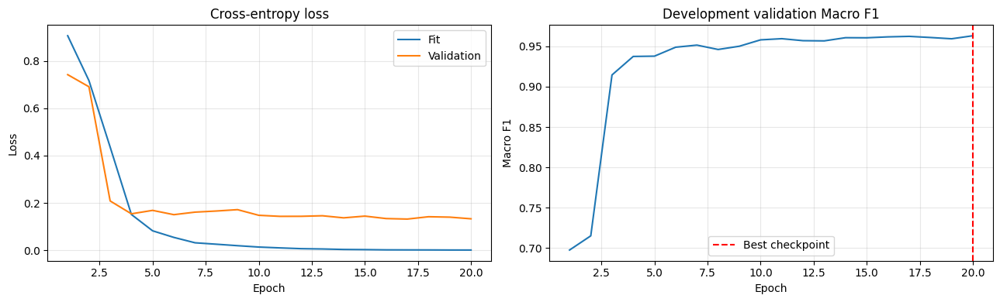

ผล 5 epochs สุดท้าย


,epoch,train_loss,val_loss,macro_f1
15,16,0.002023,0.134071,0.961757
16,17,0.001821,0.131946,0.962375
17,18,0.001662,0.141800,0.960979
18,19,0.001332,0.140053,0.959393
19,20,0.001257,0.133085,0.963138


F1 แต่ละคลาส ณ best epoch


,class,game,validation_f1
0,0,7-11 Knights,0.982043
1,1,FiveN,0.963979
2,2,Free Fried,0.968061
3,3,PUBE,0.960710
4,4,Roblock,0.940898


In [24]:
import matplotlib.pyplot as plt

# ใช้ผลจาก baseline ที่เพิ่งรันใน notebook รอบนี้
run_dir = best_run_dir

history = pd.read_csv(run_dir / "history.csv")

best_row = history.sort_values(
    ["macro_f1", "val_loss"],
    ascending=[False, True],
).iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history["epoch"], history["train_loss"], label="Fit")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
axes[0].set_title("Cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history["epoch"], history["macro_f1"])
axes[1].axvline(
    best_row["epoch"],
    color="red",
    linestyle="--",
    label="Best checkpoint",
)
axes[1].set_title("Development validation Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("ผล 5 epochs สุดท้าย")
display(
    history[
        ["epoch", "train_loss", "val_loss", "macro_f1"]
    ].tail()
)

print("F1 แต่ละคลาส ณ best epoch")
display(pd.DataFrame({
    "class": range(5),
    "game": CLASS_NAMES,
    "validation_f1": [
        best_row[f"f1_class_{label}"] for label in range(5)
    ],
}))

ดู confusion matrix ของ best checkpoint

ตรวจ Macro F1 จากไฟล์ที่บันทึก: 0.96314


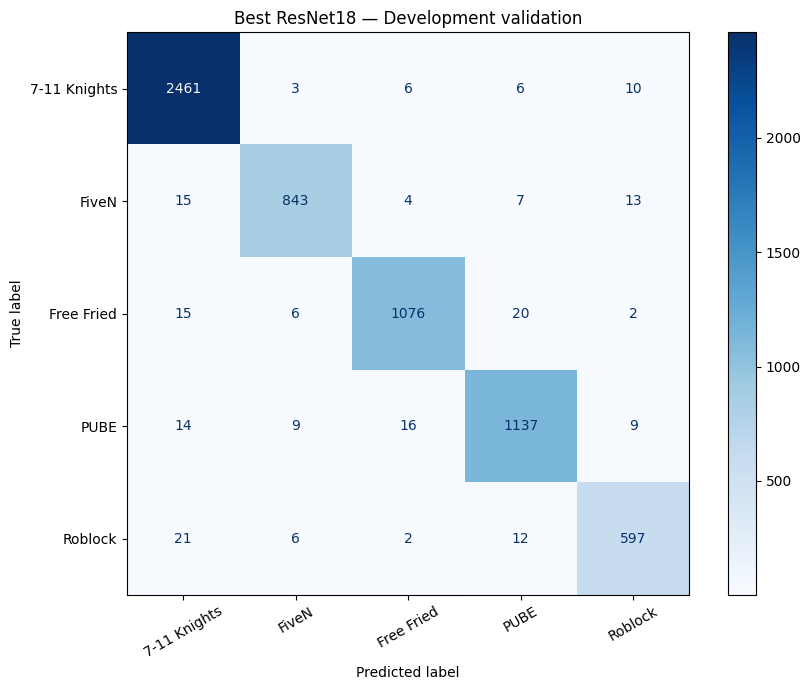

,precision,recall,f1-score,support
7-11 Knights,0.974268,0.989944,0.982043,2486.000000
FiveN,0.972318,0.955782,0.963979,882.000000
Free Fried,0.974638,0.961573,0.968061,1119.000000
PUBE,0.961929,0.959494,0.960710,1185.000000
Roblock,0.946117,0.935737,0.940898,638.000000
accuracy,0.968938,0.968938,0.968938,0.968938
macro avg,0.965854,0.960506,0.963138,6310.000000
weighted avg,0.968897,0.968938,0.968872,6310.000000


จำนวนภาพที่ทายผิด: 196


In [25]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
)

with np.load(run_dir / "best_validation.npz", allow_pickle=False) as saved:
    val_probabilities = saved["probabilities"].copy()
    val_targets = saved["targets"].copy()
    saved_ids = saved["image_id"].copy()

# ตรวจว่าผลตรงกับ validation ที่ใช้อยู่
assert saved_ids.tolist() == val_df["id"].tolist()
assert np.array_equal(
    val_targets,
    val_df["label"].astype(int).to_numpy(),
)
assert val_probabilities.shape == (len(val_df), 5)
assert np.isfinite(val_probabilities).all()
assert np.allclose(val_probabilities.sum(axis=1), 1, atol=1e-5)

val_predictions = val_probabilities.argmax(axis=1)

score = f1_score(
    val_targets,
    val_predictions,
    labels=list(range(5)),
    average="macro",
    zero_division=0,
)
assert np.isclose(score, best_row["macro_f1"])
print(f"ตรวจ Macro F1 จากไฟล์ที่บันทึก: {score:.5f}")

matrix = confusion_matrix(
    val_targets, val_predictions, labels=list(range(5))
)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=CLASS_NAMES,
).plot(ax=ax, cmap="Blues", xticks_rotation=30)

ax.set_title("Best ResNet18 — Development validation")
plt.tight_layout()
plt.show()

report = classification_report(
    val_targets,
    val_predictions,
    labels=list(range(5)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
display(pd.DataFrame(report).T)

print("จำนวนภาพที่ทายผิด:", int((val_predictions != val_targets).sum()))

เช็คดูภาพที่โมเดลทายผิดด้วยความมั่นใจสูง

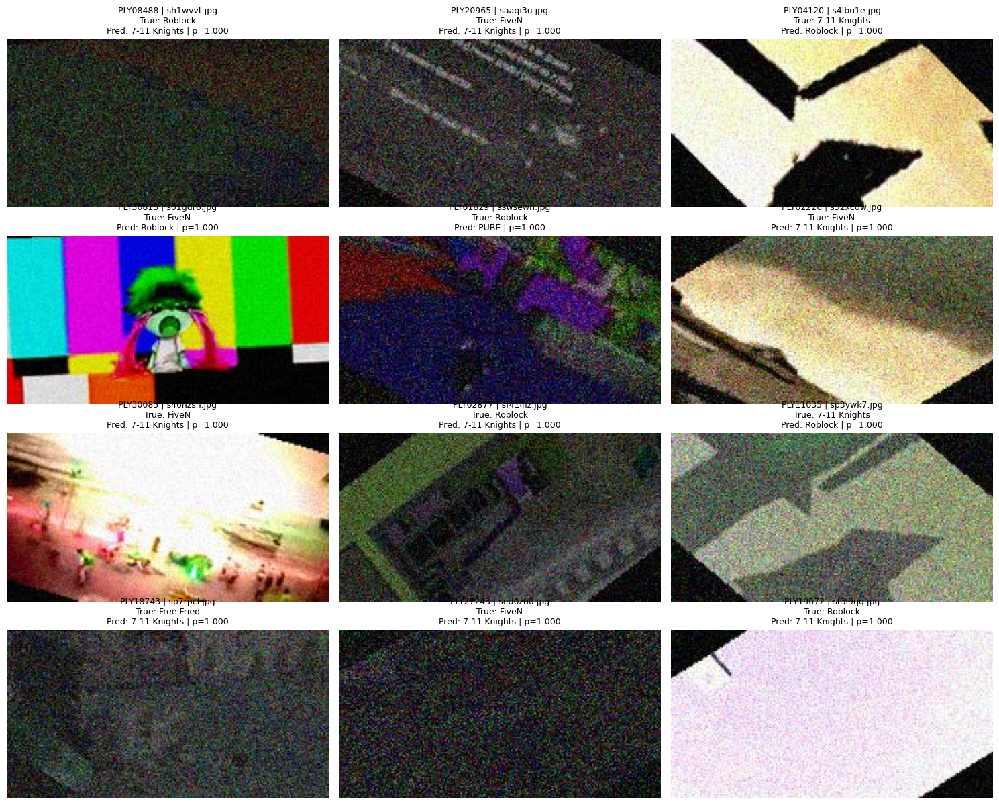

,id,file_name,true_class,predicted_class,confidence
1702,PLY08488,sh1wvvt.jpg,4,0,0.999995
4182,PLY20965,saaqi3u.jpg,1,0,0.999994
817,PLY04120,s4lbu1e.jpg,0,4,0.999977
6168,PLY30813,s01gdr6.jpg,1,4,0.999968
373,PLY01829,sswsewh.jpg,4,3,0.999967
457,PLY02226,s52xc0w.jpg,1,0,0.999957
6011,PLY30085,s46nzsh.jpg,1,0,0.999952
595,PLY02877,sf414iz.jpg,4,0,0.999863
2215,PLY11035,sp3ywk7.jpg,0,4,0.999838
3743,PLY18743,sp7rpcl.jpg,2,0,0.999762


In [26]:
error_analysis = val_df.copy()
error_analysis["true_class"] = val_targets
error_analysis["predicted_class"] = val_predictions
error_analysis["confidence"] = val_probabilities.max(axis=1)
error_analysis["correct"] = val_predictions == val_targets

wrong_images = error_analysis.loc[
    ~error_analysis["correct"]
].sort_values("confidence", ascending=False)

examples = wrong_images.head(12)

fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(axes.flat, examples.itertuples(index=False)):
    path = DATA_DIR / "train" / row.file_name

    with Image.open(path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"{row.id} | {row.file_name}\n"
        f"True: {CLASS_NAMES[row.true_class]}\n"
        f"Pred: {CLASS_NAMES[row.predicted_class]} "
        f"| p={row.confidence:.3f}",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

display(
    examples[
        ["id", "file_name", "true_class", "predicted_class", "confidence"]
    ]
)

การตรวจภาพทายผิดที่มีความมั่นใจสูงพบว่า หลายภาพมีความมืด ความสว่าง หรือ noise จนบดบังรายละเอียดของฉากและ UI โมเดลยังสามารถให้ softmax สูงกับคำทำนายที่ผิดได้ แสดงข้อจำกัดของการใช้ softmax เป็นความมั่นใจ ผลนี้มาจากตัวอย่างข้อผิดพลาด 12 ภาพ ไม่ใช่ข้อสรุปสาเหตุของข้อผิดพลาดทั้งหมด และไม่มีการแก้ labels จากคำทำนาย

### เตรียม Test DataLoader และโหลด best checkpoint

In [27]:
class GameTestDataset(Dataset):
    def __init__(self, frame, image_root, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.image_root = image_root
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        path = self.image_root / row["file_name"]

        with Image.open(path) as source:
            image = ImageOps.exif_transpose(source).convert("RGB")
            tensor = self.transform(image)

        return tensor


# Test ใช้ transform แบบไม่สุ่มเหมือน Validation
test_dataset = GameTestDataset(
    test_df,
    DATA_DIR / "test",
    val_transform,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,  # รักษาลำดับ test.csv
    num_workers=0,
    pin_memory=True,
)

# โหลด checkpoint ที่เราสร้างเอง
checkpoint = torch.load(
    run_dir / "best.pt",
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["run_info"]["class_names"] == CLASS_NAMES
assert checkpoint["run_info"]["image_size"] == list(IMAGE_SIZE)
assert (
    checkpoint["run_info"]["split_metadata"]["split_manifest_sha256"]
    == metadata["split_manifest_sha256"]
)

# ไม่ต้องดาวน์โหลด pretrained เพราะจะโหลดน้ำหนักจาก checkpoint
best_model = resnet18(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, 5)
best_model.load_state_dict(checkpoint["state_dict"])
best_model = best_model.to(DEVICE).eval()

print("Checkpoint epoch:", checkpoint["epoch"])
print("Development Macro F1:", checkpoint["metrics"]["macro_f1"])

# ทดสอบ Test หนึ่ง batch
test_images = next(iter(test_loader))

with torch.inference_mode():
    test_logits = best_model(test_images.to(DEVICE))

assert test_logits.shape == (len(test_images), 5)
assert torch.isfinite(test_logits).all()

print("Test images:", len(test_dataset))
print("Test batch shape:", tuple(test_images.shape))
print("Test output shape:", tuple(test_logits.shape))
print("เตรียม Test inference ผ่าน")

del checkpoint, test_images, test_logits
torch.cuda.empty_cache()

Checkpoint epoch: 20
Development Macro F1: 0.9631383592615694
Test images: 25889
Test batch shape: (16, 3, 128, 256)
Test output shape: (16, 5)
เตรียม Test inference ผ่าน


### ทำนาย Test ทั้งชุดและบันทึก id,task4

In [28]:
import time

# ตรวจ ID ก่อนเริ่ม inference
sample_df = pd.read_csv(
    PROJECT_ROOT / "data/raw/sample_submission.csv",
    dtype=str,
    keep_default_na=False,
)

assert test_df["id"].is_unique
assert sample_df["id"].is_unique
assert test_df["id"].tolist() == sample_df["id"].tolist()
assert len(test_dataset) == len(test_df)

all_test_probabilities = []
started = time.perf_counter()
completed = 0

best_model.eval()

with torch.inference_mode():
    for images in test_loader:
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=TRAIN_CONFIG["amp"],
        ):
            logits = best_model(
                images.to(DEVICE, non_blocking=True)
            )

        probabilities = logits.float().softmax(dim=1)
        assert torch.isfinite(probabilities).all()

        all_test_probabilities.append(probabilities.cpu().numpy())
        completed += len(images)

        if len(all_test_probabilities) % 200 == 0 or completed == len(test_df):
            print(f"ทำนายแล้ว {completed:,}/{len(test_df):,} ภาพ")

test_probabilities = np.concatenate(all_test_probabilities)

assert test_probabilities.shape == (len(test_df), 5)
assert np.isfinite(test_probabilities).all()
assert np.allclose(test_probabilities.sum(axis=1), 1, atol=1e-5)

task4_predictions = pd.DataFrame({
    "id": test_df["id"].to_numpy(),
    "task4": test_probabilities.argmax(axis=1).astype(np.int64),
})

assert task4_predictions.columns.tolist() == ["id", "task4"]
assert task4_predictions["id"].is_unique
assert task4_predictions.notna().all().all()
assert task4_predictions["task4"].isin(range(5)).all()
assert task4_predictions["id"].tolist() == sample_df["id"].tolist()

# แยกโฟลเดอร์ตามรอบฝึก เพื่อไม่ทับผลรอบอื่น
prediction_dir = PROJECT_ROOT / "submissions" / run_dir.name
prediction_dir.mkdir(parents=True, exist_ok=True)
prediction_path = prediction_dir / "task4.csv"

# ไม่เขียนทับ CSV ที่มีเนื้อหาต่างกัน
csv_bytes = task4_predictions.to_csv(
    index=False, lineterminator="\n"
).encode("utf-8")

if prediction_path.exists() and prediction_path.read_bytes() != csv_bytes:
    raise FileExistsError("มี task4.csv ที่ต่างกันอยู่แล้ว ให้ตรวจก่อนเขียนทับ")

prediction_path.write_bytes(csv_bytes)

# อ่านกลับเพื่อตรวจรูปแบบและค่าทุกแถว
reloaded = pd.read_csv(prediction_path, dtype={"id": str})
pd.testing.assert_frame_equal(reloaded, task4_predictions)

# เก็บ probabilities พร้อม IDs ไว้ในผลการทดลอง
np.savez_compressed(
    run_dir / "test_probabilities.npz",
    probabilities=test_probabilities,
    image_id=test_df["id"].to_numpy(dtype=str),
)

print(f"\nใช้เวลา {time.perf_counter() - started:.1f} วินาที")
print("บันทึก:", prediction_path)
print("จำนวนแถว:", len(reloaded))
print("SHA256:", hashlib.sha256(prediction_path.read_bytes()).hexdigest())
display(reloaded.head())
print("ทำนายและตรวจไฟล์ Task 4 ผ่าน")

ทำนายแล้ว 3,200/25,889 ภาพ
ทำนายแล้ว 6,400/25,889 ภาพ
ทำนายแล้ว 9,600/25,889 ภาพ
ทำนายแล้ว 12,800/25,889 ภาพ
ทำนายแล้ว 16,000/25,889 ภาพ
ทำนายแล้ว 19,200/25,889 ภาพ
ทำนายแล้ว 22,400/25,889 ภาพ
ทำนายแล้ว 25,600/25,889 ภาพ
ทำนายแล้ว 25,889/25,889 ภาพ

ใช้เวลา 125.5 วินาที
บันทึก: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\submissions\resnet18_20261124_155809_039967\task4.csv
จำนวนแถว: 25889
SHA256: 6b4283983e263e6baf8dcde820df4d8bd550fade78d39c01e5891a18d6be650d


,id,task4
0,ANS00001,0
1,ANS00002,2
2,ANS00003,3
3,ANS00004,0
4,ANS00005,3


ทำนายและตรวจไฟล์ Task 4 ผ่าน


### เตรียม frozen encoder

In [29]:
from torchvision.models import resnet18, ResNet18_Weights
from torch import nn
from torch.nn import functional as F

# ใช้ ImageNet weights ใหม่ ไม่ใช้ checkpoint ที่ fine-tune แล้ว
frozen_network = resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1
)

frozen_encoder = nn.Sequential(
    *list(frozen_network.children())[:-2]
).to(DEVICE)

del frozen_network

frozen_encoder.eval()
frozen_encoder.requires_grad_(False)


@torch.inference_mode()
def extract_frozen_features(images):
    # ใช้ float32 โดยไม่เปิด autocast
    activation = frozen_encoder(
        images.to(DEVICE, non_blocking=True)
    )

    spatial = F.adaptive_avg_pool2d(
        activation, (2, 4)
    ).flatten(1)

    global_features = F.adaptive_avg_pool2d(
        activation, (1, 1)
    ).flatten(1)

    return torch.cat([spatial, global_features], dim=1)


images, _ = next(iter(val_loader))
features = extract_frozen_features(images)

assert features.shape == (len(images), 4608)
assert torch.isfinite(features).all()
assert not any(
    p.requires_grad for p in frozen_encoder.parameters()
)

print("Feature shape:", tuple(features.shape))
print("Frozen encoder: พร้อม")
print("ยังไม่ฝึก classifier head")

del images, features
torch.cuda.empty_cache()

Feature shape: (16, 4608)
Frozen encoder: พร้อม
ยังไม่ฝึก classifier head


สกัดและบันทึก features ของ Fit และ Validation
เราจะใช้ภาพแบบ ไม่สุ่ม augmentation ทั้งสองฝั่ง แล้วเก็บ features เป็น float16

In [30]:
from datetime import datetime
import time

# แยกผลจาก baseline และสร้างโฟลเดอร์ใหม่ทุกครั้ง
frozen_run_dir = (
    PROJECT_ROOT / "models" / "Task4"
    / ("frozen_resnet18_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
)
frozen_run_dir.mkdir(parents=True, exist_ok=False)

FEATURE_SPEC = {
    "backbone": "resnet18",
    "weights": "IMAGENET1K_V1",
    "image_size": list(IMAGE_SIZE),
    "spatial_pool": [2, 4],
    "global_pool": [1, 1],
    "dimension": 4608,
    "cache_dtype": "float16",
    "normalization_mean": list(MEAN),
    "normalization_std": list(STD),
    "augmentation": "none",
    "backbone_frozen": True,
}


def cache_features(frame, split_name):
    # ใช้ val_transform เพื่อไม่สุ่มสี และไม่ shuffle
    dataset = GameDataset(
        frame, DATA_DIR / "train", val_transform
    )
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )

    destination = frozen_run_dir / f"{split_name}_features.npy"
    temporary = frozen_run_dir / f"{split_name}_features.partial.npy"

    cache = np.lib.format.open_memmap(
        temporary,
        mode="w+",
        dtype=np.float16,
        shape=(len(frame), FEATURE_SPEC["dimension"]),
    )

    offset = 0
    started = time.perf_counter()

    frozen_encoder.eval()

    for batch_number, (images, _) in enumerate(loader, start=1):
        values = (
            extract_frozen_features(images)
            .cpu().numpy().astype(np.float16)
        )

        assert values.shape == (len(images), 4608)
        assert np.isfinite(values).all()

        cache[offset:offset + len(values)] = values
        offset += len(values)

        if batch_number % 200 == 0 or offset == len(frame):
            print(
                f"{split_name}: {offset:,}/{len(frame):,} ภาพ "
                f"| {time.perf_counter() - started:.1f} วินาที"
            )

    assert offset == len(frame)

    cache.flush()
    del cache
    temporary.replace(destination)

    # บันทึกลำดับแถวคู่กับ features
    frame[["id", "file_name", "label", "duplicate_group"]].to_csv(
        frozen_run_dir / f"{split_name}_rows.csv",
        index=False,
    )

    return destination


fit_feature_path = cache_features(fit_df, "fit")
val_feature_path = cache_features(val_df, "validation")

cache_metadata = {
    "feature_spec": FEATURE_SPEC,
    "split_metadata": metadata,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "device": str(DEVICE),
}

(frozen_run_dir / "feature_metadata.json").write_text(
    json.dumps(cache_metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# เปิดแบบ memory map ไม่ต้องโหลดทั้งหมดเข้า RAM ทันที
fit_features = np.load(fit_feature_path, mmap_mode="r")
val_features = np.load(val_feature_path, mmap_mode="r")

assert fit_features.shape == (len(fit_df), 4608)
assert val_features.shape == (len(val_df), 4608)

print("\nFit features:", fit_features.shape, fit_features.dtype)
print("Validation features:", val_features.shape, val_features.dtype)
print("บันทึกที่:", frozen_run_dir)
print("Feature cache: ผ่าน")

fit: 3,200/25,236 ภาพ | 17.5 วินาที
fit: 6,400/25,236 ภาพ | 35.7 วินาที
fit: 9,600/25,236 ภาพ | 52.8 วินาที
fit: 12,800/25,236 ภาพ | 71.5 วินาที
fit: 16,000/25,236 ภาพ | 87.7 วินาที
fit: 19,200/25,236 ภาพ | 103.9 วินาที
fit: 22,400/25,236 ภาพ | 120.2 วินาที
fit: 25,236/25,236 ภาพ | 134.9 วินาที
validation: 3,200/6,310 ภาพ | 16.2 วินาที
validation: 6,310/6,310 ภาพ | 32.2 วินาที

Fit features: (25236, 4608) float16
Validation features: (6310, 4608) float16
บันทึกที่: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\models\Task4\frozen_resnet18_20261124_173109_797753
Feature cache: ผ่าน


### Normalize features โดยใช้สถิติจาก Fit เท่านั้น

In [31]:
# แปลงเป็น float32 สำหรับคำนวณสถิติและฝึก head
fit_values = np.array(fit_features, dtype=np.float32, copy=True)

feature_mean = fit_values.mean(axis=0)
feature_scale = np.maximum(fit_values.std(axis=0), 0.05)

fit_values -= feature_mean
fit_values /= feature_scale

# Validation ใช้สถิติจาก Fit ไม่คำนวณใหม่
val_values = np.array(val_features, dtype=np.float32, copy=True)
val_values -= feature_mean
val_values /= feature_scale

assert feature_mean.shape == feature_scale.shape == (4608,)
assert np.isfinite(fit_values).all()
assert np.isfinite(val_values).all()
assert (feature_scale >= 0.05).all()

# เก็บ tensors บน CPU ตามแนวทางฝึก head ใน notebook เสริม
x_fit = torch.from_numpy(fit_values)
x_val = torch.from_numpy(val_values)

y_fit = torch.from_numpy(
    fit_df["label"].to_numpy(dtype=np.int64, copy=True)
)
y_val = torch.from_numpy(
    val_df["label"].to_numpy(dtype=np.int64, copy=True)
)

assert x_fit.shape == (len(y_fit), 4608)
assert x_val.shape == (len(y_val), 4608)
assert set(y_fit.tolist()) == set(y_val.tolist()) == set(range(5))

# บันทึกไว้ใช้กับข้อมูลใหม่ภายหลัง
np.savez_compressed(
    frozen_run_dir / "development_normalization.npz",
    mean=feature_mean,
    scale=feature_scale,
)

print("Fit:", tuple(x_fit.shape), x_fit.dtype, x_fit.device)
print("Validation:", tuple(x_val.shape), x_val.dtype, x_val.device)
print("Normalization fit: Fit partition only")
print("เตรียม features และ labels ผ่าน")

Fit: (25236, 4608) torch.float32 cpu
Validation: (6310, 4608) torch.float32 cpu
Normalization fit: Fit partition only
เตรียม features และ labels ผ่าน


เตรียม linear และ MLP head  
- Linear: ชั้น Linear(4608, 5)
- MLP: Dropout → Linear(4608, 256) → ReLU → Dropout → Linear(256, 5)

In [32]:
# แยก config จาก baseline ที่ fine-tune ไปแล้ว
HEAD_CONFIG = {
    "seed": 342,
    "max_epochs": 35,
    "batch_size": 512,
    "lr": 0.001,
    "weight_decay": 0.001,
    "min_lr": 1e-5,
    "patience": 6,
    "cpu_threads": 4,
}

torch.set_num_threads(HEAD_CONFIG["cpu_threads"])


def build_frozen_head(kind):
    if kind == "linear":
        return nn.Linear(4608, 5)

    if kind == "mlp":
        return nn.Sequential(
            nn.Dropout(0.15),
            nn.Linear(4608, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(256, 5),
        )

    raise ValueError(f"ไม่รู้จัก head: {kind}")


# ทดสอบโครงสร้างเท่านั้น ยังไม่มี optimizer หรือการฝึก
for kind in ["linear", "mlp"]:
    torch.manual_seed(HEAD_CONFIG["seed"])
    head = build_frozen_head(kind).eval()

    with torch.inference_mode():
        logits = head(x_val[:16])

    assert logits.shape == (16, 5)
    assert torch.isfinite(logits).all()

    print(
        f"{kind}: output={tuple(logits.shape)} | "
        f"parameters={sum(p.numel() for p in head.parameters()):,}"
    )

    del head, logits

display(pd.Series(HEAD_CONFIG, name="value").to_frame())
print("Linear/MLP head test: ผ่าน — ยังไม่เริ่มฝึก")

linear: output=(16, 5) | parameters=23,045
mlp: output=(16, 5) | parameters=1,181,189


,value
seed,342.00000
max_epochs,35.00000
batch_size,512.00000
lr,0.00100
weight_decay,0.00100
min_lr,0.00001
patience,6.00000
cpu_threads,4.00000


Linear/MLP head test: ผ่าน — ยังไม่เริ่มฝึก


### เตรียมฟังก์ชันฝึก head และบันทึก checkpoint

In [33]:
from sklearn.metrics import f1_score, log_loss
import time


@torch.inference_mode()
def predict_head(head, values):
    head.eval()
    batches = [
        head(values[start:start + 1024]).softmax(dim=1).numpy()
        for start in range(0, len(values), 1024)
    ]
    probabilities = np.concatenate(batches)

    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)
    return probabilities


def train_frozen_head(kind):
    torch.manual_seed(HEAD_CONFIG["seed"])
    np.random.seed(HEAD_CONFIG["seed"])

    directory = frozen_run_dir / kind
    directory.mkdir(exist_ok=False)  # ไม่เขียนทับรอบเดิม

    head = build_frozen_head(kind)
    optimizer = torch.optim.AdamW(
        head.parameters(),
        lr=HEAD_CONFIG["lr"],
        weight_decay=HEAD_CONFIG["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=HEAD_CONFIG["max_epochs"],
        eta_min=HEAD_CONFIG["min_lr"],
    )

    loader = DataLoader(
        torch.utils.data.TensorDataset(x_fit, y_fit),
        batch_size=HEAD_CONFIG["batch_size"],
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(HEAD_CONFIG["seed"]),
    )

    history = []
    best_key = (-float("inf"), -float("inf"))
    best_result = None
    stale = 0
    targets = y_val.numpy()

    for epoch in range(HEAD_CONFIG["max_epochs"]):
        started = time.perf_counter()
        head.train()
        loss_sum = 0.0
        seen = 0
        current_lr = optimizer.param_groups[0]["lr"]

        for features, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            logits = head(features)
            loss = F.cross_entropy(logits, labels)

            if not torch.isfinite(loss):
                raise FloatingPointError("พบ training loss ไม่เป็นค่าจำกัด")

            loss.backward()
            nn.utils.clip_grad_norm_(head.parameters(), 5.0)
            optimizer.step()

            loss_sum += loss.detach().item() * len(labels)
            seen += len(labels)

        assert seen == len(y_fit)
        scheduler.step()

        probabilities = predict_head(head, x_val)
        score = float(f1_score(
            targets,
            probabilities.argmax(axis=1),
            labels=list(range(5)),
            average="macro",
            zero_division=0,
        ))
        val_loss = float(log_loss(
            targets, probabilities, labels=list(range(5))
        ))

        row = {
            "epoch": epoch + 1,
            "train_loss": loss_sum / seen,
            "val_loss": val_loss,
            "macro_f1": score,
            "lr": current_lr,
            "seconds": time.perf_counter() - started,
        }
        history.append(row)
        pd.DataFrame(history).to_csv(
            directory / "history.csv", index=False
        )

        print(
            f"{kind} epoch {epoch + 1}: "
            f"train_loss={row['train_loss']:.4f} | "
            f"val_loss={val_loss:.4f} | Macro F1={score:.5f}"
        )

        key = (score, -val_loss)
        if key > best_key:
            best_key = key
            stale = 0
            best_result = {"kind": kind, **row}

            torch.save(
                {
                    "head_state_dict": head.state_dict(),
                    "kind": kind,
                    "epoch": epoch + 1,
                    "macro_f1": score,
                    "val_loss": val_loss,
                    "config": HEAD_CONFIG,
                    "feature_spec": FEATURE_SPEC,
                    "split_metadata": metadata,
                    "mean": torch.from_numpy(feature_mean.copy()),
                    "scale": torch.from_numpy(feature_scale.copy()),
                },
                directory / "best.pt",
            )
            np.savez_compressed(
                directory / "best_validation.npz",
                probabilities=probabilities,
                image_id=val_df["id"].to_numpy(dtype=str),
                targets=targets,
            )
        else:
            stale += 1

        if stale >= HEAD_CONFIG["patience"]:
            print("Early stopping:", kind)
            break

    (directory / "result.json").write_text(
        json.dumps(best_result, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print(
        f"Best {kind}: epoch {best_result['epoch']} | "
        f"Macro F1={best_result['macro_f1']:.5f}"
    )
    return best_result


print("เตรียมฟังก์ชันฝึก head แล้ว — ยังไม่เริ่มฝึก")

เตรียมฟังก์ชันฝึก head แล้ว — ยังไม่เริ่มฝึก


### train Linear และ MLP head

In [34]:
linear_result = train_frozen_head("linear")
mlp_result = train_frozen_head("mlp")

head_comparison = pd.DataFrame([
    linear_result,
    mlp_result,
]).sort_values(
    ["macro_f1", "val_loss"],
    ascending=[False, True],
)

display(
    head_comparison[
        ["kind", "epoch", "train_loss", "val_loss", "macro_f1"]
    ]
)

head_comparison.to_csv(
    frozen_run_dir / "head_comparison.csv",
    index=False,
)

print("Selected head:", head_comparison.iloc[0]["kind"])
print("ฝึกและเปรียบเทียบ head เสร็จแล้ว")

linear epoch 1: train_loss=0.7122 | val_loss=0.5196 | Macro F1=0.79108
linear epoch 2: train_loss=0.4450 | val_loss=0.4787 | Macro F1=0.80227
linear epoch 3: train_loss=0.3852 | val_loss=0.4502 | Macro F1=0.82151
linear epoch 4: train_loss=0.3484 | val_loss=0.4479 | Macro F1=0.82024
linear epoch 5: train_loss=0.3207 | val_loss=0.4339 | Macro F1=0.82936
linear epoch 6: train_loss=0.2972 | val_loss=0.4370 | Macro F1=0.82245
linear epoch 7: train_loss=0.2833 | val_loss=0.4312 | Macro F1=0.82689
linear epoch 8: train_loss=0.2676 | val_loss=0.4364 | Macro F1=0.82819
linear epoch 9: train_loss=0.2576 | val_loss=0.4415 | Macro F1=0.82438
linear epoch 10: train_loss=0.2432 | val_loss=0.4370 | Macro F1=0.82808
linear epoch 11: train_loss=0.2346 | val_loss=0.4345 | Macro F1=0.82820
Early stopping: linear
Best linear: epoch 5 | Macro F1=0.82936
mlp epoch 1: train_loss=0.6257 | val_loss=0.4229 | Macro F1=0.82417
mlp epoch 2: train_loss=0.3581 | val_loss=0.3898 | Macro F1=0.83633
mlp epoch 3: train

,kind,epoch,train_loss,val_loss,macro_f1
1,mlp,34,0.023424,0.440851,0.87662
0,linear,5,0.320728,0.433889,0.82936


Selected head: mlp
ฝึกและเปรียบเทียบ head เสร็จแล้ว


ทดลองผสม probabilities บน Validation

In [35]:
# โหลดผลของ best checkpoints ทั้งสองวิธี
selected_kind = head_comparison.iloc[0]["kind"]

with np.load(run_dir / "best_validation.npz", allow_pickle=False) as saved:
    base_probs = saved["probabilities"].copy()
    base_ids = saved["image_id"].copy()
    blend_targets = saved["targets"].copy()

with np.load(
    frozen_run_dir / selected_kind / "best_validation.npz",
    allow_pickle=False,
) as saved:
    head_probs = saved["probabilities"].copy()
    head_ids = saved["image_id"].copy()
    head_targets = saved["targets"].copy()

# จัดลำดับ head predictions ด้วย IDs ให้ตรง baseline
assert pd.Index(base_ids).is_unique
assert pd.Index(head_ids).is_unique
assert len(base_ids) == len(head_ids)

order = pd.Index(head_ids).get_indexer(base_ids)
assert (order >= 0).all()

head_probs = head_probs[order]
head_targets = head_targets[order]

assert base_ids.tolist() == val_df["id"].tolist()
assert np.array_equal(blend_targets, head_targets)
assert np.array_equal(
    blend_targets, val_df["label"].astype(int).to_numpy()
)

blend_rows = []

for weight in [0.0, 0.025, 0.05, 0.075, 0.1, 0.15,
               0.2, 0.25, 0.35, 0.5, 1.0]:
    combined = (1 - weight) * base_probs + weight * head_probs

    assert np.isfinite(combined).all()
    assert np.allclose(combined.sum(axis=1), 1, atol=1e-5)

    blend_rows.append({
        "frozen_head_weight": weight,
        "baseline_weight": 1 - weight,
        "macro_f1": float(f1_score(
            blend_targets,
            combined.argmax(axis=1),
            labels=list(range(5)),
            average="macro",
            zero_division=0,
        )),
        "val_loss": float(log_loss(
            blend_targets, combined, labels=list(range(5))
        )),
    })

blend_comparison = pd.DataFrame(blend_rows)

# F1 สูงสุด → loss ต่ำสุด → น้ำหนัก head ต่ำสุด
ranked_blends = blend_comparison.sort_values(
    ["macro_f1", "val_loss", "frozen_head_weight"],
    ascending=[False, True, True],
)

chosen_blend = ranked_blends.iloc[0]
baseline_score = blend_comparison.loc[
    blend_comparison["frozen_head_weight"].eq(0), "macro_f1"
].iloc[0]

blend_comparison.to_csv(
    frozen_run_dir / "blend_comparison.csv", index=False
)

display(ranked_blends)
print("Selected frozen head:", selected_kind)
print("Selected head weight:", chosen_blend["frozen_head_weight"])
print("Selected Macro F1:", chosen_blend["macro_f1"])
print("F1 gain:", chosen_blend["macro_f1"] - baseline_score)

,frozen_head_weight,baseline_weight,macro_f1,val_loss
8,0.350,0.650,0.964615,0.129910
4,0.100,0.900,0.964326,0.112702
3,0.075,0.925,0.963848,0.112662
2,0.050,0.950,0.963848,0.113455
5,0.150,0.850,0.963617,0.114222
7,0.250,0.750,0.963608,0.120585
1,0.025,0.975,0.963231,0.115925
6,0.200,0.800,0.963139,0.116968
0,0.000,1.000,0.963138,0.132438
9,0.500,0.500,0.957942,0.148804


Selected frozen head: mlp
Selected head weight: 0.35
Selected Macro F1: 0.9646150700354644
F1 gain: 0.0014767107738949958


ตรวจว่า blend แก้ภาพผิดและทำภาพเดิมเสียกี่ภาพ

In [36]:
selected_weight = float(chosen_blend["frozen_head_weight"])

selected_blend_probs = (
    (1 - selected_weight) * base_probs
    + selected_weight * head_probs
)

base_pred = base_probs.argmax(axis=1)
blend_pred = selected_blend_probs.argmax(axis=1)

base_correct = base_pred == blend_targets
blend_correct = blend_pred == blend_targets

fixed = (~base_correct) & blend_correct
broken = base_correct & (~blend_correct)

verified_score = f1_score(
    blend_targets,
    blend_pred,
    labels=list(range(5)),
    average="macro",
    zero_division=0,
)
assert np.isclose(verified_score, chosen_blend["macro_f1"])

print("Baseline ทายผิด:", int((~base_correct).sum()))
print("Blend ทายผิด:", int((~blend_correct).sum()))
print("Blend แก้จากผิดเป็นถูก:", int(fixed.sum()))
print("Blend เปลี่ยนจากถูกเป็นผิด:", int(broken.sum()))

class_comparison = pd.DataFrame({
    "game": CLASS_NAMES,
    "baseline_f1": f1_score(
        blend_targets, base_pred,
        labels=list(range(5)), average=None, zero_division=0,
    ),
    "blend_f1": f1_score(
        blend_targets, blend_pred,
        labels=list(range(5)), average=None, zero_division=0,
    ),
})
class_comparison["gain"] = (
    class_comparison["blend_f1"] - class_comparison["baseline_f1"]
)
display(class_comparison)

# เก็บผลทดลองแยกจาก baseline
np.savez_compressed(
    frozen_run_dir / "blend_validation.npz",
    probabilities=selected_blend_probs,
    image_id=base_ids,
    targets=blend_targets,
)

blend_recipe = {
    "baseline_checkpoint": str(run_dir / "best.pt"),
    "head_checkpoint": str(frozen_run_dir / selected_kind / "best.pt"),
    "selected_head": selected_kind,
    "baseline_weight": 1 - selected_weight,
    "frozen_head_weight": selected_weight,
    "development_macro_f1": float(verified_score),
    "development_gain": float(verified_score - baseline_score),
    "split_manifest_sha256": metadata["split_manifest_sha256"],
    "head_full_train_refit": False,
    "selection_note": "Weights selected on development validation.",
}

(frozen_run_dir / "blend_recipe.json").write_text(
    json.dumps(blend_recipe, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("บันทึกผลและสูตร blend แล้ว")

Baseline ทายผิด: 196
Blend ทายผิด: 189
Blend แก้จากผิดเป็นถูก: 19
Blend เปลี่ยนจากถูกเป็นผิด: 12


,game,baseline_f1,blend_f1,gain
0,7-11 Knights,0.982043,0.982036,-0.000007
1,FiveN,0.963979,0.964143,0.000164
2,Free Fried,0.968061,0.968933,0.000872
3,PUBE,0.960710,0.964090,0.003380
4,Roblock,0.940898,0.943874,0.002975


บันทึกผลและสูตร blend แล้ว


### เตรียม features สำหรับ full-train refit

In [37]:
# ตรวจว่า features เรียงตรงกับแถวที่บันทึกไว้
for split_name, frame in [("fit", fit_df), ("validation", val_df)]:
    saved_rows = pd.read_csv(
        frozen_run_dir / f"{split_name}_rows.csv",
        dtype=str,
        keep_default_na=False,
    )
    assert saved_rows["id"].tolist() == frame["id"].tolist()

# รวม raw features โดยจัดกลับเข้าลำดับ train.csv
train_ids = pd.Index(train_df["id"])
assert train_ids.is_unique

fit_positions = train_ids.get_indexer(fit_df["id"])
val_positions = train_ids.get_indexer(val_df["id"])

all_positions = np.concatenate([fit_positions, val_positions])
assert (all_positions >= 0).all()
assert len(np.unique(all_positions)) == len(train_df)
assert len(all_positions) == len(train_df)

full_values = np.empty((len(train_df), 4608), dtype=np.float32)
full_values[fit_positions] = fit_features
full_values[val_positions] = val_features

# Refit preprocessing บน Train ทั้งหมด หลังล็อกสูตรแล้ว
full_mean = full_values.mean(axis=0)
full_scale = np.maximum(full_values.std(axis=0), 0.05)

full_values -= full_mean
full_values /= full_scale

assert np.isfinite(full_values).all()

x_full = torch.from_numpy(full_values)
y_full = torch.from_numpy(
    train_df["label"].to_numpy(dtype=np.int64, copy=True)
)

selected_result = head_comparison.loc[
    head_comparison["kind"].eq(selected_kind)
].iloc[0]
REFIT_EPOCHS = int(selected_result["epoch"])

assert 1 <= REFIT_EPOCHS <= HEAD_CONFIG["max_epochs"]

np.savez_compressed(
    frozen_run_dir / "full_train_normalization.npz",
    mean=full_mean,
    scale=full_scale,
)

print("Full Train features:", tuple(x_full.shape))
print("Full Train labels:", tuple(y_full.shape))
print("Selected head:", selected_kind)
print("Refit epochs:", REFIT_EPOCHS)
print("เตรียม full-train refit ผ่าน — ยังไม่เริ่มฝึก")

Full Train features: (31546, 4608)
Full Train labels: (31546,)
Selected head: mlp
Refit epochs: 34
เตรียม full-train refit ผ่าน — ยังไม่เริ่มฝึก


ฝึก MLP head ใหม่บน Train

In [38]:
final_head_path = frozen_run_dir / "full_train_head.pt"
full_history_path = frozen_run_dir / "full_train_history.csv"

if final_head_path.exists() or full_history_path.exists():
    raise FileExistsError(
        "พบผล full-train refit อยู่แล้ว ให้ตรวจสอบก่อนรันซ้ำ"
    )

torch.manual_seed(HEAD_CONFIG["seed"])
np.random.seed(HEAD_CONFIG["seed"])

final_head = build_frozen_head(selected_kind)

full_optimizer = torch.optim.AdamW(
    final_head.parameters(),
    lr=HEAD_CONFIG["lr"],
    weight_decay=HEAD_CONFIG["weight_decay"],
)

# ใช้ trajectory เดิม: T_max=35 แล้วหยุดที่ epoch ที่เลือกไว้
full_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    full_optimizer,
    T_max=HEAD_CONFIG["max_epochs"],
    eta_min=HEAD_CONFIG["min_lr"],
)

full_loader = DataLoader(
    torch.utils.data.TensorDataset(x_full, y_full),
    batch_size=HEAD_CONFIG["batch_size"],
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(HEAD_CONFIG["seed"]),
)

full_history = []

for epoch in range(REFIT_EPOCHS):
    started = time.perf_counter()
    final_head.train()
    loss_sum = 0.0
    seen = 0
    current_lr = full_optimizer.param_groups[0]["lr"]

    for features, labels in full_loader:
        full_optimizer.zero_grad(set_to_none=True)

        loss = F.cross_entropy(final_head(features), labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("พบ nonfinite loss ระหว่าง refit")

        loss.backward()
        nn.utils.clip_grad_norm_(final_head.parameters(), 5.0)
        full_optimizer.step()

        loss_sum += loss.detach().item() * len(labels)
        seen += len(labels)

    assert seen == len(train_df)
    full_scheduler.step()

    row = {
        "epoch": epoch + 1,
        "train_loss": loss_sum / seen,
        "lr": current_lr,
        "seconds": time.perf_counter() - started,
    }
    full_history.append(row)
    pd.DataFrame(full_history).to_csv(full_history_path, index=False)

    print(
        f"Refit {epoch + 1}/{REFIT_EPOCHS} | "
        f"train_loss={row['train_loss']:.4f} | "
        f"{row['seconds']:.1f} วินาที"
    )

final_head.eval()

# เก็บทั้ง encoder, head และ preprocessing ที่ใช้คู่กัน
payload = {
    "encoder_state_dict": {
        name: tensor.detach().cpu().clone()
        for name, tensor in frozen_encoder.state_dict().items()
    },
    "head_state_dict": final_head.state_dict(),
    "kind": selected_kind,
    "epochs": REFIT_EPOCHS,
    "mean": torch.from_numpy(full_mean.copy()),
    "scale": torch.from_numpy(full_scale.copy()),
    "feature_spec": FEATURE_SPEC,
    "class_names": CLASS_NAMES,
    "config": HEAD_CONFIG,
    "split_metadata": metadata,
    "full_train_refit": True,
    "development_head_macro_f1": float(selected_result["macro_f1"]),
    "validation_macro_f1_of_final_refit": None,
}

temporary_path = final_head_path.with_suffix(".pt.tmp")
torch.save(payload, temporary_path)
temporary_path.replace(final_head_path)

# ตรวจว่าโหลด head กลับมาแล้วทำนายได้เหมือนเดิม
restored = torch.load(
    final_head_path, map_location="cpu", weights_only=True
)
restored_head = build_frozen_head(restored["kind"])
restored_head.load_state_dict(restored["head_state_dict"])

np.testing.assert_allclose(
    predict_head(final_head, x_full[:8]),
    predict_head(restored_head, x_full[:8]),
    rtol=1e-6,
    atol=1e-7,
)

del payload, restored, restored_head
del full_optimizer, full_scheduler

print("\nบันทึก:", final_head_path)
print("Full-train refit และทดสอบโหลด checkpoint: ผ่าน")

Refit 1/34 | train_loss=0.5881 | 5.4 วินาที
Refit 2/34 | train_loss=0.3472 | 5.2 วินาที
Refit 3/34 | train_loss=0.2760 | 6.7 วินาที
Refit 4/34 | train_loss=0.2263 | 5.2 วินาที
Refit 5/34 | train_loss=0.1954 | 5.2 วินาที
Refit 6/34 | train_loss=0.1744 | 5.1 วินาที
Refit 7/34 | train_loss=0.1482 | 5.0 วินาที
Refit 8/34 | train_loss=0.1367 | 5.2 วินาที
Refit 9/34 | train_loss=0.1222 | 5.2 วินาที
Refit 10/34 | train_loss=0.1135 | 5.5 วินาที
Refit 11/34 | train_loss=0.0959 | 5.4 วินาที
Refit 12/34 | train_loss=0.0954 | 4.9 วินาที
Refit 13/34 | train_loss=0.0839 | 5.0 วินาที
Refit 14/34 | train_loss=0.0805 | 5.3 วินาที
Refit 15/34 | train_loss=0.0708 | 5.0 วินาที
Refit 16/34 | train_loss=0.0666 | 5.1 วินาที
Refit 17/34 | train_loss=0.0603 | 5.1 วินาที
Refit 18/34 | train_loss=0.0569 | 5.1 วินาที
Refit 19/34 | train_loss=0.0501 | 5.1 วินาที
Refit 20/34 | train_loss=0.0480 | 5.4 วินาที
Refit 21/34 | train_loss=0.0420 | 5.8 วินาที
Refit 22/34 | train_loss=0.0422 | 8.1 วินาที
Refit 23/34 | train

ทำนาย Test ด้วย frozen ResNet18 + MLP ที่ฝึกใหม่

In [39]:
frozen_test_path = frozen_run_dir / "full_train_test_probabilities.npz"

if frozen_test_path.exists():
    raise FileExistsError("มีผล Test รอบนี้แล้ว ให้ตรวจสอบก่อนรันซ้ำ")

# โหลดชุดโมเดลและ preprocessing ที่บันทึกไว้
restored = torch.load(
    final_head_path, map_location="cpu", weights_only=True
)

assert restored["full_train_refit"] is True
assert restored["class_names"] == CLASS_NAMES
assert restored["feature_spec"] == FEATURE_SPEC

encoder_base = resnet18(weights=None)
frozen_encoder = nn.Sequential(*list(encoder_base.children())[:-2])
del encoder_base

frozen_encoder.load_state_dict(restored["encoder_state_dict"])
frozen_encoder = frozen_encoder.to(DEVICE).eval()
frozen_encoder.requires_grad_(False)

refit_head = build_frozen_head(restored["kind"])
refit_head.load_state_dict(restored["head_state_dict"])
refit_head.eval()

refit_mean = restored["mean"].numpy()
refit_scale = restored["scale"].numpy()
del restored

# ยืนยันว่า Test loader รักษาลำดับและไม่มีการสุ่ม augmentation
assert isinstance(
    test_loader.sampler, torch.utils.data.SequentialSampler
)
assert test_dataset.frame["id"].tolist() == test_df["id"].tolist()
assert test_dataset.transform is val_transform

frozen_test_batches = []
completed = 0
started = time.perf_counter()

with torch.inference_mode():
    for images in test_loader:
        raw_features = extract_frozen_features(images).cpu().numpy()

        # ให้สอดคล้องกับ features ฝั่ง Train ที่ cache เป็น float16
        raw_features = raw_features.astype(np.float16).astype(np.float32)
        assert np.isfinite(raw_features).all()

        normalized = (raw_features - refit_mean) / refit_scale
        probabilities = predict_head(
            refit_head, torch.from_numpy(normalized)
        )

        frozen_test_batches.append(probabilities)
        completed += len(images)

        if len(frozen_test_batches) % 200 == 0 or completed == len(test_df):
            print(f"ทำนายแล้ว {completed:,}/{len(test_df):,} ภาพ")

frozen_test_probs = np.concatenate(frozen_test_batches)

assert frozen_test_probs.shape == (len(test_df), 5)
assert np.isfinite(frozen_test_probs).all()
assert np.allclose(frozen_test_probs.sum(axis=1), 1, atol=1e-5)

np.savez_compressed(
    frozen_test_path,
    probabilities=frozen_test_probs,
    image_id=test_df["id"].to_numpy(dtype=str),
)

# อ่านกลับเพื่อตรวจค่าที่บันทึก
with np.load(frozen_test_path, allow_pickle=False) as saved:
    assert saved["image_id"].tolist() == test_df["id"].tolist()
    np.testing.assert_array_equal(
        saved["probabilities"], frozen_test_probs
    )

print("\nProbability shape:", frozen_test_probs.shape)
print(f"ใช้เวลา: {time.perf_counter() - started:.1f} วินาที")
print("บันทึก:", frozen_test_path)
print("Frozen/MLP Test inference: ผ่าน")

ทำนายแล้ว 3,200/25,889 ภาพ
ทำนายแล้ว 6,400/25,889 ภาพ
ทำนายแล้ว 9,600/25,889 ภาพ
ทำนายแล้ว 12,800/25,889 ภาพ
ทำนายแล้ว 16,000/25,889 ภาพ
ทำนายแล้ว 19,200/25,889 ภาพ
ทำนายแล้ว 22,400/25,889 ภาพ
ทำนายแล้ว 25,600/25,889 ภาพ
ทำนายแล้ว 25,889/25,889 ภาพ

Probability shape: (25889, 5)
ใช้เวลา: 131.3 วินาที
บันทึก: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\models\Task4\frozen_resnet18_20261124_173109_797753\full_train_test_probabilities.npz
Frozen/MLP Test inference: ผ่าน


ผสม probabilities แล้วสร้าง CSV ใหม่

In [40]:
# อ่านน้ำหนักที่ล็อกจาก development validation
recipe = json.loads(
    (frozen_run_dir / "blend_recipe.json").read_text(encoding="utf-8")
)
head_weight = float(recipe["frozen_head_weight"])
base_weight = float(recipe["baseline_weight"])

# ใช้น้ำหนักที่เลือกและบันทึกไว้ในรอบนี้
assert 0.0 <= head_weight <= 1.0
assert np.isclose(base_weight + head_weight, 1.0)

sample_df = pd.read_csv(
    PROJECT_ROOT / "data/raw/sample_submission.csv",
    dtype=str,
    keep_default_na=False,
)
ordered_ids = sample_df["id"].tolist()

assert sample_df["id"].is_unique
assert sample_df["id"].ne("").all()
assert test_df["id"].tolist() == ordered_ids


def load_aligned_probabilities(path, target_ids):
    with np.load(path, allow_pickle=False) as saved:
        ids = saved["image_id"].copy()
        probabilities = saved["probabilities"].copy()

    index = pd.Index(ids)
    assert index.is_unique
    assert len(ids) == len(target_ids)
    assert probabilities.shape == (len(ids), 5)
    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)

    order = index.get_indexer(target_ids)
    assert (order >= 0).all()
    return probabilities[order]


base_test_probs = load_aligned_probabilities(
    run_dir / "test_probabilities.npz", ordered_ids
)
head_test_probs = load_aligned_probabilities(
    frozen_test_path, ordered_ids
)

# ยืนยันว่า baseline probabilities ตรงกับ CSV รอบแรก
baseline_csv = (
    PROJECT_ROOT / "submissions" / run_dir.name / "task4.csv"
)
baseline_predictions = pd.read_csv(baseline_csv, dtype={"id": str})

assert baseline_predictions["id"].is_unique
assert len(baseline_predictions) == len(ordered_ids)

baseline_labels = (
    baseline_predictions.set_index("id")
    .loc[ordered_ids, "task4"]
    .to_numpy()
)
assert np.array_equal(base_test_probs.argmax(axis=1), baseline_labels)

# ผสม probabilities ก่อนเลือกคลาส
blend_test_probs = (
    base_weight * base_test_probs
    + head_weight * head_test_probs
)
assert np.isfinite(blend_test_probs).all()
assert np.allclose(blend_test_probs.sum(axis=1), 1, atol=1e-5)

blend_submission = pd.DataFrame({
    "id": ordered_ids,
    "task4": blend_test_probs.argmax(axis=1).astype(np.int64),
})

assert blend_submission.columns.tolist() == ["id", "task4"]
assert blend_submission.notna().all().all()
assert blend_submission["task4"].isin(range(5)).all()

output_dir = PROJECT_ROOT / "submissions" / frozen_run_dir.name
output_dir.mkdir(parents=True, exist_ok=True)
blend_csv_path = output_dir / "task4_blend.csv"

csv_bytes = blend_submission.to_csv(
    index=False, lineterminator="\n"
).encode("utf-8")

if blend_csv_path.exists() and blend_csv_path.read_bytes() != csv_bytes:
    raise FileExistsError("มี CSV ที่ต่างกันอยู่แล้ว ไม่เขียนทับ")

blend_csv_path.write_bytes(csv_bytes)

reloaded = pd.read_csv(blend_csv_path, dtype={"id": str})
pd.testing.assert_frame_equal(reloaded, blend_submission)

csv_sha256 = hashlib.sha256(csv_bytes).hexdigest()

export_info = {
    "baseline_checkpoint": str(run_dir / "best.pt"),
    "full_train_head_checkpoint": str(final_head_path),
    "baseline_probabilities_sha256": hashlib.sha256(
        (run_dir / "test_probabilities.npz").read_bytes()
    ).hexdigest(),
    "head_probabilities_sha256": hashlib.sha256(
        frozen_test_path.read_bytes()
    ).hexdigest(),
    "baseline_weight": base_weight,
    "frozen_head_weight": head_weight,
    "head_full_train_refit": True,
    "development_blend_macro_f1_before_refit":
        recipe["development_macro_f1"],
    "validation_macro_f1_after_refit": None,
    "kaggle_score": None,
    "rows": len(reloaded),
    "csv_sha256": csv_sha256,
}

(output_dir / "prediction_metadata.json").write_text(
    json.dumps(export_info, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("บันทึก:", blend_csv_path)
print("จำนวนแถว:", len(reloaded))
print("SHA256:", csv_sha256)
print(
    "คำทำนายที่ต่างจาก baseline:",
    int((reloaded["task4"].to_numpy() != baseline_labels).sum()),
)
display(reloaded.head())
print("สร้างและตรวจไฟล์ blend ผ่าน")

บันทึก: C:\Users\Kittithat\Player-Intelligence-System-CPE342-ML\submissions\frozen_resnet18_20261124_173109_797753\task4_blend.csv
จำนวนแถว: 25889
SHA256: 18c1d0401f6ca09e0fb8049225166c07955d7b20faa9c926cb845e5306b57fe2
คำทำนายที่ต่างจาก baseline: 985


,id,task4
0,ANS00001,0
1,ANS00002,2
2,ANS00003,3
3,ANS00004,0
4,ANS00005,3


สร้างและตรวจไฟล์ blend ผ่าน
